In [84]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rohanrao/formula-1-world-championship-1950-2020")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020


# 1. Exploratory Data Analysis (EDA)
## 1.1 Loading the Dataset

In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Specify the exact dataset location
data_path = Path('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020')

# Load all CSV files from this dataset only
files = list(data_path.glob('*.csv'))

data = {}

for file in files:
    data[file.stem] = pd.read_csv(
        file,
        dtype=str,
        keep_default_na=False
    )

print("Number of datasets:", len(data))
print("Loaded datasets:", list(data.keys()))
print("Dataset location:", data_path)

Number of datasets: 14
Loaded datasets: ['races', 'constructor_results', 'drivers', 'constructors', 'lap_times', 'status', 'driver_standings', 'seasons', 'pit_stops', 'sprint_results', 'constructor_standings', 'results', 'circuits', 'qualifying']
Dataset location: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020


## 1.2 Initial Data Inspection

In [86]:
# Inspect all datasets
for name, df in data.items():
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

# Display the main tables
display(data['results'].head())
display(data['races'].head())
display(data['qualifying'].head())

# Check missing values and duplicates
summary = []

for name, df in data.items():
    missing = (df == r'\N') | (df == '')

    summary.append({
        'Dataset': name,
        'Rows': df.shape[0],
        'Columns': df.shape[1],
        'Missing Values': missing.sum().sum(),
        'Missing %': missing.sum().sum() / df.size * 100,
        'Duplicates': df.duplicated().sum()
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

# Check repeated driver-race combinations
print(
    "Duplicate driver-race records:",
    data['results'].duplicated(
        ['raceId', 'driverId']
    ).sum()
)


races
Shape: (1125, 18)
Columns: ['raceId', 'year', 'round', 'circuitId', 'name', 'date', 'time', 'url', 'fp1_date', 'fp1_time', 'fp2_date', 'fp2_time', 'fp3_date', 'fp3_time', 'quali_date', 'quali_time', 'sprint_date', 'sprint_time']

constructor_results
Shape: (12625, 5)
Columns: ['constructorResultsId', 'raceId', 'constructorId', 'points', 'status']

drivers
Shape: (861, 9)
Columns: ['driverId', 'driverRef', 'number', 'code', 'forename', 'surname', 'dob', 'nationality', 'url']

constructors
Shape: (212, 5)
Columns: ['constructorId', 'constructorRef', 'name', 'nationality', 'url']

lap_times
Shape: (589081, 6)
Columns: ['raceId', 'driverId', 'lap', 'position', 'time', 'milliseconds']

status
Shape: (139, 2)
Columns: ['statusId', 'status']

driver_standings
Shape: (34863, 7)
Columns: ['driverStandingsId', 'raceId', 'driverId', 'points', 'position', 'positionText', 'wins']

seasons
Shape: (75, 2)
Columns: ['year', 'url']

pit_stops
Shape: (11371, 7)
Columns: ['raceId', 'driverId', 'st

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4,58,+18.014,5708630,43,1,1:27.418,218.385,1


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


,Dataset,Rows,Columns,Missing Values,Missing %,Duplicates
0,races,1125,18,11349,56.044444,0
1,constructor_results,12625,5,12608,19.973069,0
2,drivers,861,9,1559,20.118725,0
3,constructors,212,5,0,0.000000,0
4,lap_times,589081,6,0,0.000000,0
5,status,139,2,0,0.000000,0
6,driver_standings,34863,7,0,0.000000,0
7,seasons,75,2,0,0.000000,0
8,pit_stops,11371,7,0,0.000000,0
9,sprint_results,360,16,73,1.267361,0


Duplicate driver-race records: 91


## 1.3 Missing Values Visualization

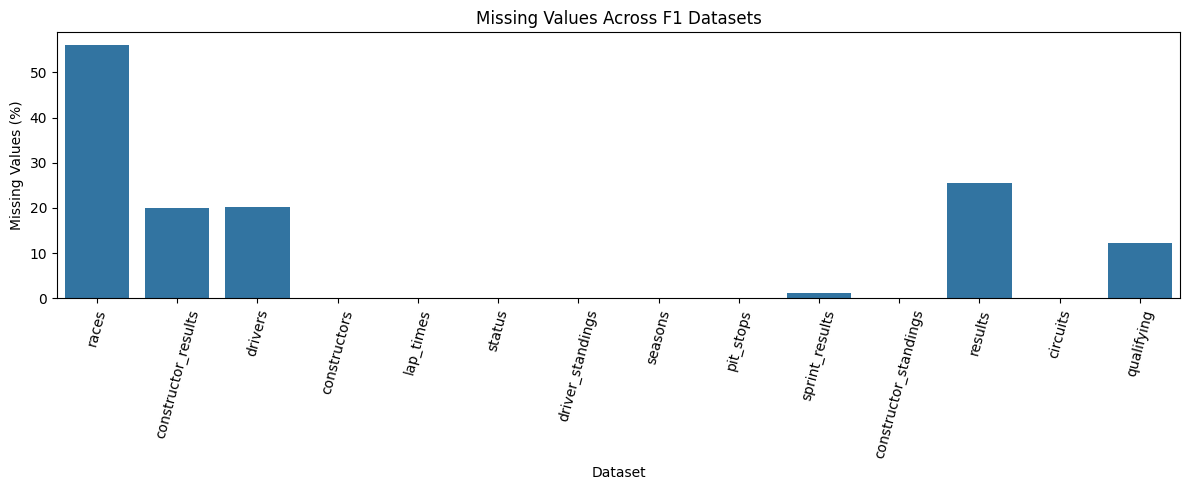

In [87]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=summary_df,
    x='Dataset',
    y='Missing %'
)

plt.title('Missing Values Across F1 Datasets')
plt.xlabel('Dataset')
plt.ylabel('Missing Values (%)')

plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

## 1.4 Starting Position and Podium Analysis

,grid,positionOrder
count,26759.000000,26759.000000
mean,11.134796,12.794051
std,7.202860,7.665951
min,0.000000,1.000000
25%,5.000000,6.000000
50%,11.000000,12.000000
75%,17.000000,18.000000
max,34.000000,39.000000


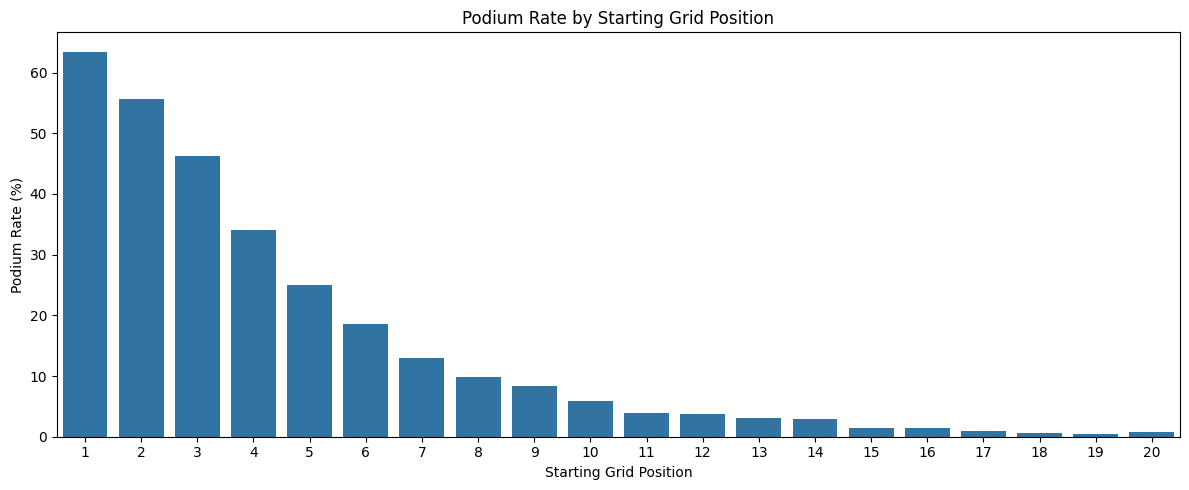

In [88]:
# Create a temporary DataFrame for EDA
df = data['results'].copy()

# Convert columns to numerical values
df['grid'] = pd.to_numeric(df['grid'], errors='coerce')
df['positionOrder'] = pd.to_numeric(
    df['positionOrder'],
    errors='coerce'
)

# Explore numerical statistics
display(df[['grid', 'positionOrder']].describe())

# Create podium indicator
df['podium'] = (df['positionOrder'] <= 3).astype(int)

# Analyze the first 20 starting positions
grid_data = df[
    df['grid'].between(1, 20)
    & df['positionOrder'].notna()
]

# Calculate podium percentage
podium_rate = (
    grid_data.groupby('grid')['podium'].mean() * 100
)

# Visualization
plt.figure(figsize=(12, 5))

sns.barplot(
    x=podium_rate.index,
    y=podium_rate.values
)

plt.title('Podium Rate by Starting Grid Position')
plt.xlabel('Starting Grid Position')
plt.ylabel('Podium Rate (%)')

plt.tight_layout()
plt.show()

# 2. Data Cleaning
## 2.1 Missing Values and Data Types

In [89]:
# Create copies to preserve original data
clean = {}

for name, df in data.items():
    clean[name] = df.copy()
    clean[name] = clean[name].replace([r'\N', ''], np.nan)


# Convert numerical columns
numeric_columns = [
    'raceId', 'driverId', 'constructorId', 'circuitId',
    'resultId', 'qualifyId', 'statusId',
    'constructorResultsId', 'constructorStandingsId',
    'driverStandingsId', 'year', 'round', 'number',
    'grid', 'position', 'positionOrder', 'points',
    'laps', 'milliseconds', 'fastestLap',
    'fastestLapSpeed', 'rank', 'wins',
    'lap', 'stop', 'lat', 'lng', 'alt'
]

for name, df in clean.items():
    for col in numeric_columns:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')


# Convert dates
date_columns = [
    'date', 'dob', 'fp1_date', 'fp2_date',
    'fp3_date', 'quali_date', 'sprint_date'
]

for name, df in clean.items():
    for col in date_columns:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col], errors='coerce')


# Convert durations to seconds
def to_seconds(value):
    if pd.isna(value):
        return np.nan

    try:
        parts = list(map(float, str(value).split(':')))

        if len(parts) == 1:
            return parts[0]
        if len(parts) == 2:
            return parts[0] * 60 + parts[1]
        if len(parts) == 3:
            return parts[0] * 3600 + parts[1] * 60 + parts[2]
    except ValueError:
        pass

    return np.nan


duration_columns = {
    'qualifying': ['q1', 'q2', 'q3'],
    'lap_times': ['time'],
    'pit_stops': ['duration'],
    'results': ['fastestLapTime'],
    'sprint_results': ['fastestLapTime']
}

for table, columns in duration_columns.items():
    for col in columns:
        if col in clean[table].columns:
            clean[table][col + '_seconds'] = (
                clean[table][col].apply(to_seconds)
            )

print("Missing values and data types cleaned successfully.")

Missing values and data types cleaned successfully.


## 2.2 Primary-Key Validation

In [90]:
primary_keys = {
    'circuits': ['circuitId'],
    'constructors': ['constructorId'],
    'constructor_results': ['constructorResultsId'],
    'constructor_standings': ['constructorStandingsId'],
    'drivers': ['driverId'],
    'driver_standings': ['driverStandingsId'],
    'races': ['raceId'],
    'results': ['resultId'],
    'qualifying': ['qualifyId'],
    'lap_times': ['raceId', 'driverId', 'lap'],
    'pit_stops': ['raceId', 'driverId', 'stop'],
    'sprint_results': ['resultId'],
    'seasons': ['year'],
    'status': ['statusId']
}

pk_results = []

for name, keys in primary_keys.items():
    df = clean[name]

    pk_results.append({
        'Table': name,
        'Missing Keys': df[keys].isnull().any(axis=1).sum(),
        'Duplicate Keys': df.duplicated(subset=keys).sum()
    })

display(pd.DataFrame(pk_results))

,Table,Missing Keys,Duplicate Keys
0,circuits,0,0
1,constructors,0,0
2,constructor_results,0,0
3,constructor_standings,0,0
4,drivers,0,0
5,driver_standings,0,0
6,races,0,0
7,results,0,0
8,qualifying,0,0
9,lap_times,0,0


## 2.3 Foreign-Key Validation

In [91]:
foreign_keys = {
    'raceId': 'races',
    'driverId': 'drivers',
    'constructorId': 'constructors',
    'circuitId': 'circuits',
    'statusId': 'status',
    'year': 'seasons'
}

fk_results = []

for name, df in clean.items():

    for key, parent in foreign_keys.items():

        if key in df.columns and name != parent:

            invalid = (
                df[key].notna()
                & ~df[key].isin(clean[parent][key])
            )

            fk_results.append({
                'Table': name,
                'Foreign Key': key,
                'Invalid References': invalid.sum()
            })

display(pd.DataFrame(fk_results))

,Table,Foreign Key,Invalid References
0,races,circuitId,0
1,races,year,0
2,constructor_results,raceId,0
3,constructor_results,constructorId,0
4,lap_times,raceId,0
5,lap_times,driverId,0
6,driver_standings,raceId,0
7,driver_standings,driverId,0
8,pit_stops,raceId,0
9,pit_stops,driverId,0


## 2.4 Duplicate Driver-Race Handling

In [92]:
results_clean = clean['results'].copy()

# Investigate historical duplicates
duplicates = results_clean[
    results_clean.duplicated(
        ['raceId', 'driverId'],
        keep=False
    )
]

display(
    duplicates[
        ['raceId', 'driverId', 'resultId',
         'grid', 'positionOrder']
    ].sort_values(['raceId', 'driverId']).head(20)
)

# Define the podium target across shared-drive records
podium_labels = (
    results_clean.assign(
        podium=(results_clean['positionOrder'] <= 3).astype(int)
    )
    .groupby(['raceId', 'driverId'])['podium']
    .max()
    .reset_index()
)

# Prefer the smallest valid starting-grid position
results_clean['valid_grid'] = (
    results_clean['grid'].where(
        results_clean['grid'] > 0,
        np.inf
    )
)

results_clean = results_clean.sort_values(
    ['raceId', 'driverId', 'valid_grid', 'resultId']
)

results_clean = results_clean.drop_duplicates(
    subset=['raceId', 'driverId'],
    keep='first'
)

results_clean = results_clean.drop(columns=['valid_grid'])

results_clean = results_clean.merge(
    podium_labels,
    on=['raceId', 'driverId'],
    validate='one_to_one'
)

print(
    "Remaining duplicate driver-race records:",
    results_clean.duplicated(['raceId', 'driverId']).sum()
)

print("Final number of records:", len(results_clean))

,raceId,driverId,resultId,grid,positionOrder
13188,540,229,13189,0,26
13191,540,229,13192,0,29
17362,717,373,17363,1,7
24298,717,373,24304,1,12
17740,733,465,17741,0,22
17743,733,465,17744,0,25
17961,742,475,17962,20,19
17963,742,475,17964,5,21
18062,745,418,18063,11,17
24297,745,418,24303,15,11


Remaining duplicate driver-race records: 0
Final number of records: 26668


/usr/local/lib/python3.13/dist-packages/pandas/core/dtypes/cast.py:377: RuntimeWarning: invalid value encountered in cast
  new_result = trans(result).astype(dtype)


# 3. EDA After Cleaning

,Table,Before,After
0,races,11349,11349
1,constructor_results,12608,12608
2,drivers,1559,1559
3,constructors,0,0
4,lap_times,0,0
5,status,0,0
6,driver_standings,0,0
7,seasons,0,0
8,pit_stops,0,0
9,sprint_results,73,73


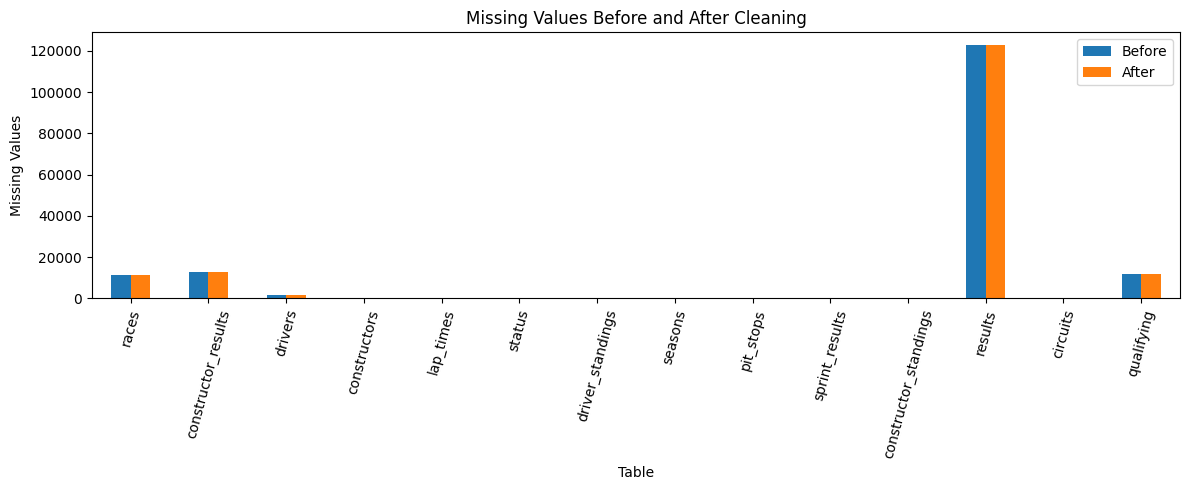

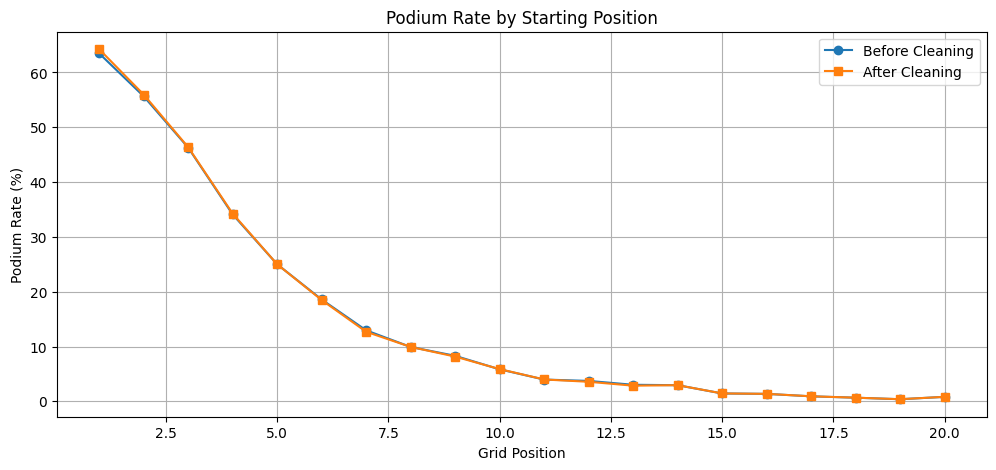

Rows before: 26759
Rows after: 26668


In [93]:
# Compare missing values
comparison = []

for name in data:

    before = (
        (data[name] == r'\N') |
        (data[name] == '')
    ).sum().sum()

    after = clean[name][data[name].columns].isnull().sum().sum()

    comparison.append({
        'Table': name,
        'Before': before,
        'After': after
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df)

comparison_df.set_index('Table').plot(
    kind='bar',
    figsize=(12, 5)
)

plt.title('Missing Values Before and After Cleaning')
plt.ylabel('Missing Values')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


# Compare podium rates before and after duplicate handling
before_rates = (
    df.loc[df['grid'].between(1, 20)]
    .groupby('grid')['podium'].mean() * 100
) if False else None

# Use the original EDA DataFrame from Cell 4
before_rates = (
    grid_data.groupby('grid')['podium'].mean() * 100
)

after_rates = (
    results_clean[
        results_clean['grid'].between(1, 20)
    ]
    .groupby('grid')['podium'].mean() * 100
)

plt.figure(figsize=(12, 5))

plt.plot(before_rates.index, before_rates.values,
         marker='o', label='Before Cleaning')

plt.plot(after_rates.index, after_rates.values,
         marker='s', label='After Cleaning')

plt.title('Podium Rate by Starting Position')
plt.xlabel('Grid Position')
plt.ylabel('Podium Rate (%)')
plt.legend()
plt.grid(True)
plt.show()

print("Rows before:", len(data['results']))
print("Rows after:", len(results_clean))

### EDA and Data Cleaning Results

The initial EDA revealed missing values across several datasets,
particularly in the results, qualifying, and constructor_results tables.

Missing-value placeholders (\N) were converted into NaN values,
while numerical columns, dates, and durations were converted
into their appropriate data types.

Duplicate driver-race records were handled using a consistent
selection rule, reducing the results dataset from 26,759
to 26,668 records (91 records removed).

The before-and-after analysis showed that cleaning had minimal
impact on the relationship between starting position and podium finishes.

Drivers starting from the front of the grid demonstrated
significantly higher podium rates than those starting further back.

This suggests that starting-grid position is a potentially
important feature for podium prediction.

# 4. Data-Engineering Questions
## 4.1 Question 1 — Circuit Front-Row Podium Conversion

In [94]:
# Join results with races and circuits
q1 = results_clean.merge(
    clean['races'][['raceId', 'year', 'circuitId']],
    on='raceId'
)

q1 = q1.merge(
    clean['circuits'][['circuitId', 'name']],
    on='circuitId'
)

# Add qualifying positions
qualifying = clean['qualifying'][
    ['raceId', 'driverId', 'position']
].drop_duplicates(['raceId', 'driverId'])

q1 = q1.merge(
    qualifying,
    on=['raceId', 'driverId'],
    how='left'
)

q1 = q1.rename(columns={
    'position_y': 'qualifying_position',
    'position_x': 'finishing_position'
})

# Keep the required historical period
q1 = q1[q1['year'].between(1950, 2024)].copy()

# Separate the two eras
q1['Era'] = np.where(
    q1['year'] < 2014,
    'Before 2014',
    '2014–2024'
)

# Select drivers starting from the front row
front_row = q1[q1['grid'].isin([1, 2])].copy()

# Calculate podium conversion rates
circuit_rates = front_row.groupby(
    ['Era', 'name']
).agg(
    Starts=('podium', 'count'),
    Podiums=('podium', 'sum'),
    Podium_Rate=('podium', 'mean')
).reset_index()

circuit_rates['Podium_Rate'] *= 100

# Rank circuits in each era
circuit_rates['Rank'] = circuit_rates.groupby(
    'Era'
)['Podium_Rate'].rank(
    ascending=False,
    method='min'
)

# Display the highest-ranking circuits
for era in ['Before 2014', '2014–2024']:

    print(f"\nTop Circuits — {era}")

    display(
        circuit_rates[
            circuit_rates['Era'] == era
        ].sort_values(
            ['Podium_Rate', 'Starts'],
            ascending=[False, False]
        ).head(10)
    )


Top Circuits — Before 2014


,Era,name,Starts,Podiums,Podium_Rate,Rank
58,Before 2014,Circuit of the Americas,4,4,100.000000,1.0
34,Before 2014,Ain Diab,2,2,100.000000,1.0
63,Before 2014,Donington Park,2,2,100.000000,1.0
83,Before 2014,Pescara Circuit,2,2,100.000000,1.0
46,Before 2014,Buddh International Circuit,6,5,83.333333,5.0
35,Before 2014,Aintree,11,9,81.818182,6.0
55,Before 2014,Circuit de Nevers Magny-Cours,36,29,80.555556,7.0
69,Before 2014,Istanbul Park,14,11,78.571429,8.0
62,Before 2014,Dijon-Prenois,12,9,75.000000,9.0
82,Before 2014,Okayama International Circuit,4,3,75.000000,9.0



Top Circuits — 2014–2024


,Era,name,Starts,Podiums,Podium_Rate,Rank
23,2014–2024,Miami International Autodrome,6,6,100.000000,1.0
5,2014–2024,Autódromo Internacional do Algarve,4,4,100.000000,1.0
20,2014–2024,Las Vegas Strip Street Circuit,4,4,100.000000,1.0
2,2014–2024,Autodromo Internazionale del Mugello,2,2,100.000000,1.0
30,2014–2024,Suzuka Circuit,18,16,88.888889,5.0
10,2014–2024,Circuit Park Zandvoort,8,7,87.500000,6.0
19,2014–2024,Jeddah Corniche Circuit,8,7,87.500000,6.0
31,2014–2024,Yas Marina Circuit,22,19,86.363636,8.0
26,2014–2024,Sepang International Circuit,7,6,85.714286,9.0
13,2014–2024,Circuit de Monaco,20,17,85.000000,10.0


### Circuit Rankings Before and After 2014

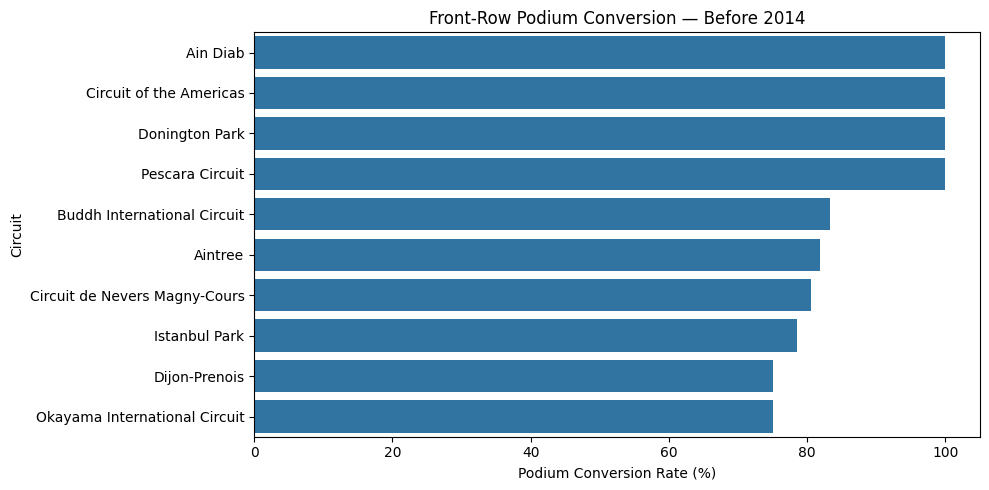

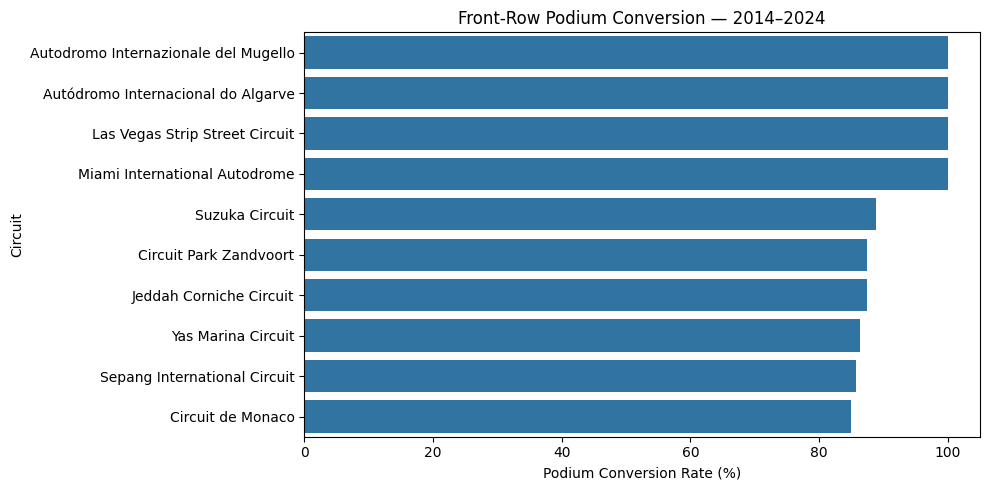

Era,2014–2024,Before 2014,Rank Before,Rank After,Rank Change
name,,,,,
Circuit de Monaco,85.000000,49.586777,23.0,5.0,-18.0
Circuit de Spa-Francorchamps,81.818182,54.347826,20.0,6.0,-14.0
Circuit Park Zandvoort,87.500000,58.333333,14.0,2.0,-12.0
Circuit Gilles Villeneuve,77.777778,52.941176,21.0,11.0,-10.0
Autodromo Nazionale di Monza,72.727273,49.218750,24.0,16.0,-8.0
Red Bull Ring,73.076923,52.000000,22.0,15.0,-7.0
Yas Marina Circuit,86.363636,60.000000,10.0,3.0,-7.0
Silverstone Circuit,75.000000,56.382979,17.0,12.0,-5.0
Circuit Paul Ricard,75.000000,57.142857,16.0,12.0,-4.0


Records where qualifying and grid positions differ: 2422
Percentage: 23.27 %


,raceId,driverId,grid,qualifying_position
0,1,1,18,15.0
1,1,2,9,11.0
3,1,4,10,12.0
4,1,5,12,14.0
5,1,6,11,13.0
6,1,7,17,20.0
7,1,8,7,9.0
9,1,10,19,6.0
10,1,12,14,17.0
11,1,13,6,7.0


In [95]:
# Visualize the top 10 circuits in each era

for era in ['Before 2014', '2014–2024']:

    top_circuits = circuit_rates[
        circuit_rates['Era'] == era
    ].nlargest(10, 'Podium_Rate')

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=top_circuits,
        x='Podium_Rate',
        y='name'
    )

    plt.title(f'Front-Row Podium Conversion — {era}')
    plt.xlabel('Podium Conversion Rate (%)')
    plt.ylabel('Circuit')

    plt.tight_layout()
    plt.show()


# Compare rankings for circuits appearing in both eras
ranking_comparison = circuit_rates.pivot(
    index='name',
    columns='Era',
    values='Podium_Rate'
).dropna()

ranking_comparison['Rank Before'] = (
    ranking_comparison['Before 2014']
    .rank(ascending=False, method='min')
)

ranking_comparison['Rank After'] = (
    ranking_comparison['2014–2024']
    .rank(ascending=False, method='min')
)

ranking_comparison['Rank Change'] = (
    ranking_comparison['Rank After']
    - ranking_comparison['Rank Before']
)

display(
    ranking_comparison.sort_values('Rank Change')
)


# Compare qualifying position with actual grid position
grid_vs_qualifying = q1[
    q1['qualifying_position'].notna()
    & q1['grid'].gt(0)
].copy()

different_positions = grid_vs_qualifying[
    grid_vs_qualifying['grid']
    != grid_vs_qualifying['qualifying_position']
]

print(
    "Records where qualifying and grid positions differ:",
    len(different_positions)
)

print(
    "Percentage:",
    round(
        len(different_positions) / len(grid_vs_qualifying) * 100,
        2
    ),
    "%"
)

display(
    different_positions[
        ['raceId', 'driverId', 'grid', 'qualifying_position']
    ].head(10)
)

### Question 1 — Results and Interpretation

**1. Front-Row Podium Conversion**

The analysis shows that podium conversion rates vary across circuits.

Before 2014, circuits such as Ain Diab, Circuit of the Americas,
Donington Park, and Pescara Circuit achieved 100% conversion rates.

From 2014 to 2024, Mugello, Algarve, Las Vegas, and Miami
also achieved 100% conversion rates.

However, some circuits have relatively few observations,
meaning their high conversion rates may not be representative
of long-term performance.

**2. Comparison Before and After 2014**

The rankings changed considerably after the introduction
of the hybrid era in 2014.

Among circuits appearing in both periods:

- Monaco improved from 49.59% to 85.00%.
- Spa-Francorchamps improved from 54.35% to 81.82%.
- Zandvoort improved from 58.33% to 87.50%.

These changes indicate that front-row podium conversion
rates differ between historical F1 eras.

**3. Qualifying Position vs. Starting Grid**

The analysis identified 2,422 records (23.27%) where
qualifying position differed from starting-grid position
among records with both positions available.

These differences may result from grid penalties or
other adjustments to the starting order.

Therefore, actual starting-grid positions (1 and 2)
were used to identify front-row starters.

**4. Data Considerations**

The analysis combines results, races, circuits, and
qualifying data using relational joins.

Each observation represents one driver participating
in one race.

Missing qualifying positions do not prevent calculating
podium conversion when the starting-grid position is known.

Finishing position is used only to determine historical
podium outcomes, not as a pre-race prediction feature.

**5. Conclusion**

Circuit rankings changed after 2014, with several circuits
showing higher front-row podium conversion rates.

However, differences in sample sizes and the number
of races hosted must be considered when interpreting
these results.

## 4.2 Question 2 — Home-Country Advantage

In [96]:
# Convert driver nationalities into country names
nationality_to_country = {
    'American': 'USA',
    'Argentine': 'Argentina',
    'Argentinian': 'Argentina',
    'Australian': 'Australia',
    'Austrian': 'Austria',
    'Belgian': 'Belgium',
    'Brazilian': 'Brazil',
    'British': 'UK',
    'Canadian': 'Canada',
    'Chilean': 'Chile',
    'Chinese': 'China',
    'Colombian': 'Colombia',
    'Czech': 'Czech Republic',
    'Danish': 'Denmark',
    'Dutch': 'Netherlands',
    'East German': 'Germany',
    'Finnish': 'Finland',
    'French': 'France',
    'German': 'Germany',
    'Hungarian': 'Hungary',
    'Indian': 'India',
    'Indonesian': 'Indonesia',
    'Irish': 'Ireland',
    'Italian': 'Italy',
    'Japanese': 'Japan',
    'Liechtensteiner': 'Liechtenstein',
    'Malaysian': 'Malaysia',
    'Mexican': 'Mexico',
    'Monegasque': 'Monaco',
    'New Zealander': 'New Zealand',
    'Polish': 'Poland',
    'Portuguese': 'Portugal',
    'Rhodesian': 'Zimbabwe',
    'Russian': 'Russia',
    'South African': 'South Africa',
    'Spanish': 'Spain',
    'Swedish': 'Sweden',
    'Swiss': 'Switzerland',
    'Thai': 'Thailand',
    'Uruguayan': 'Uruguay',
    'Venezuelan': 'Venezuela'
}

# Join results, drivers, races, and circuits
q2 = results_clean.merge(
    clean['drivers'][['driverId', 'nationality']],
    on='driverId'
)

q2 = q2.merge(
    clean['races'][['raceId', 'year', 'circuitId']],
    on='raceId'
)

q2 = q2.merge(
    clean['circuits'][['circuitId', 'country']],
    on='circuitId'
)

# Match driver nationality with circuit country
q2['driver_country'] = q2['nationality'].map(nationality_to_country)

q2['circuit_country'] = q2['country'].replace({
    'United States': 'USA',
    'United Kingdom': 'UK'
})

# Identify unmatched nationalities
print("Unmatched nationalities:")
print(q2.loc[q2['driver_country'].isna(), 'nationality'].unique())

# Keep valid records
q2 = q2[
    q2['year'].between(1950, 2024) &
    q2['driver_country'].notna() &
    q2['circuit_country'].notna() &
    q2['grid'].gt(0)
].copy()

# Identify home and away races
q2['Home_Race'] = np.where(
    q2['driver_country'] == q2['circuit_country'],
    'Home',
    'Away'
)

# Group drivers by similar starting positions
q2['Grid_Group'] = pd.cut(
    q2['grid'],
    bins=[0, 3, 6, 10, 15, np.inf],
    labels=['1-3', '4-6', '7-10', '11-15', '16+']
)

# Calculate podium rates within each grid group
home_rates = q2.groupby(
    ['Grid_Group', 'Home_Race'],
    observed=True
).agg(
    Starts=('podium', 'count'),
    Podiums=('podium', 'sum'),
    Podium_Rate=('podium', 'mean')
).reset_index()

home_rates['Podium_Rate'] *= 100

display(home_rates)

Unmatched nationalities:
['American-Italian' 'Argentine-Italian' 'Argentinian ']


,Grid_Group,Home_Race,Starts,Podiums,Podium_Rate
0,1-3,Away,3118,1733,55.580500
1,1-3,Home,267,147,55.056180
2,4-6,Away,3114,812,26.075787
3,4-6,Home,264,64,24.242424
4,7-10,Away,4115,380,9.234508
5,7-10,Home,388,33,8.505155
6,11-15,Away,5121,151,2.948643
7,11-15,Home,470,15,3.191489
8,16+,Away,7232,53,0.732854
9,16+,Home,933,7,0.750268


### Home vs Away Podium Rates by Starting Position

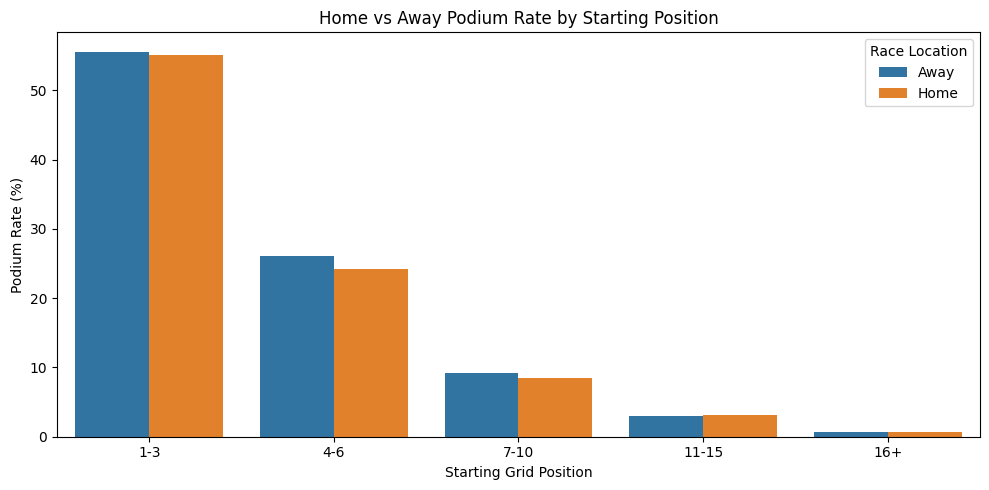

Adjusted Home Podium Rate: 13.21%
Adjusted Away Podium Rate: 13.60%
Difference: -0.39 percentage points


In [97]:
# Visualize podium rates
plt.figure(figsize=(10, 5))

sns.barplot(
    data=home_rates,
    x='Grid_Group',
    y='Podium_Rate',
    hue='Home_Race'
)

plt.title('Home vs Away Podium Rate by Starting Position')
plt.xlabel('Starting Grid Position')
plt.ylabel('Podium Rate (%)')
plt.legend(title='Race Location')

plt.tight_layout()
plt.show()


# Compare home and away rates using the same grid distribution
rates = home_rates.pivot(
    index='Grid_Group',
    columns='Home_Race',
    values='Podium_Rate'
)

# Only compare grid groups with both home and away observations
rates = rates.dropna(subset=['Home', 'Away'])

# Calculate the proportion of drivers in each grid group
weights = q2.groupby(
    'Grid_Group',
    observed=True
).size().reindex(rates.index)

weights = weights / weights.sum()

# Calculate adjusted podium rates
home_adjusted = (rates['Home'] * weights).sum()
away_adjusted = (rates['Away'] * weights).sum()

print(f"Adjusted Home Podium Rate: {home_adjusted:.2f}%")
print(f"Adjusted Away Podium Rate: {away_adjusted:.2f}%")

print(
    f"Difference: {home_adjusted - away_adjusted:.2f} percentage points"
)

### Question 2 — Results and Interpretation

**1. Home vs Away Podium Performance**

The analysis compares podium rates for drivers racing in their
home country against drivers racing elsewhere.

The comparison was performed within similar starting-grid
groups to account for differences in starting positions.

The results show that home and away podium rates are very
similar across all starting-grid groups.

**2. Results After Controlling for Grid Position**

- Adjusted Home Podium Rate: 13.21%
- Adjusted Away Podium Rate: 13.60%
- Difference: -0.39 percentage points

Drivers racing in their home country achieved a slightly lower
adjusted podium rate than drivers racing elsewhere.

However, the difference is very small, suggesting that there
is no meaningful home-country advantage evident in this analysis
after controlling for starting-grid position.

**3. Data Considerations**

The analysis combines results, drivers, races, and circuits
using relational joins.

Each observation represents one driver participating in one race.

Records with unknown starting positions or unmatched nationality
information were excluded.

Starting-grid positions were grouped into five categories:
1–3, 4–6, 7–10, 11–15, and 16+.

The adjusted podium rates were calculated using the same
grid-group distribution for home and away races.

**4. Conclusion**

The results do not show a clear home-country podium advantage.

After controlling for starting position, drivers racing at home
had a podium rate of 13.21%, compared with 13.60% when racing away.

This suggests that starting position is more strongly associated
with podium probability than home-country status.

The observed differences represent associations and do not
establish causation.

## 4.3 Question 3 — Constructor Mechanical-Retirement Rates

In [98]:
# Join results, races, constructors, and status tables
q3 = results_clean.merge(
    clean['races'][['raceId', 'year']],
    on='raceId'
)

q3 = q3.merge(
    clean['constructors'][['constructorId', 'name']],
    on='constructorId'
)

q3 = q3.merge(
    clean['status'][['statusId', 'status']],
    on='statusId'
)

# Keep races from 2014 to 2024
q3 = q3[q3['year'].between(2014, 2024)].copy()

# Examine retirement reasons
display(q3['status'].value_counts())


# Identify mechanical failures
mechanical_keywords = (
    'Engine|Gearbox|Transmission|Clutch|Hydraulics|'
    'Electrical|Radiator|Suspension|Brakes|Differential|'
    'Overheating|Mechanical|Driveshaft|Fuel pressure|'
    'Water pressure|Throttle|Steering|Technical|'
    'Electronics|Exhaust|Oil leak|Water leak|Fuel pump|'
    'Track rod|Oil pressure|Wheel nut|Pneumatics|'
    'Wheel bearing|Fuel system|Oil line|Power loss|'
    'Drivetrain|Ignition|Chassis|Battery|Halfshaft|'
    'Crankshaft|Turbo|MGU|ERS|Cooling|Alternator'
)

q3['Mechanical'] = q3['status'].str.contains(
    mechanical_keywords,
    case=False,
    regex=True,
    na=False
)

# Exclude drivers who did not start the race
non_starters = [
    'Did not start',
    'Did not qualify',
    'Did not prequalify',
    'Withdrawn',
    'Not qualified',
    'Not prequalified'
]

q3 = q3[
    ~q3['status'].str.lower().isin(
        [status.lower() for status in non_starters]
    )
].copy()

# Verify which statuses were classified as mechanical
print("Mechanical retirement reasons:")

display(
    q3[q3['Mechanical']]['status'].value_counts()
)

status
Finished          2403
+1 Lap            1178
+2 Laps            208
Collision          150
Accident            85
                  ... 
Water pump           1
Cooling system       1
Fuel pump            1
Differential         1
+7 Laps              1
Name: count, Length: 66, dtype: int64

Mechanical retirement reasons:


status
Engine            81
Brakes            49
Gearbox           42
Suspension        25
Hydraulics        15
Electrical        14
Power loss        13
Oil leak          10
Overheating        8
Mechanical         7
Water pressure     7
Turbo              6
Battery            5
Exhaust            5
ERS                5
Fuel pressure      5
Water leak         4
Electronics        4
Wheel nut          3
Transmission       3
Radiator           3
Oil pressure       2
Technical          2
Clutch             2
Steering           2
Throttle           2
Driveshaft         2
Drivetrain         1
Fuel system        1
Cooling system     1
Fuel pump          1
Differential       1
Name: count, dtype: int64

### Mechanical-Retirement Rates: 2014–2021 vs 2022–2024


Mechanical Retirement Rates — 2014–2021


,Period,name,Starts,Mechanical_Retirements,Retirement_Rate
4,2014–2021,Caterham,34,6,17.647059
8,2014–2021,Lotus F1,76,11,14.473684
17,2014–2021,Toro Rosso,242,33,13.636364
15,2014–2021,Renault,200,25,12.500000
11,2014–2021,McLaren,320,35,10.937500
16,2014–2021,Sauber,200,20,10.000000
10,2014–2021,Marussia,31,3,9.677419
14,2014–2021,Red Bull,320,30,9.375000
1,2014–2021,AlphaTauri,78,7,8.974359
13,2014–2021,Racing Point,76,6,7.894737



Mechanical Retirement Rates — 2022–2024


,Period,name,Starts,Mechanical_Retirements,Retirement_Rate
19,2022–2024,Alfa Romeo,88,10,11.363636
21,2022–2024,Alpine F1 Team,136,14,10.294118
20,2022–2024,AlphaTauri,88,4,4.545455
30,2022–2024,Williams,135,6,4.444444
26,2022–2024,Mercedes,136,6,4.411765
27,2022–2024,RB F1 Team,48,2,4.166667
25,2022–2024,McLaren,136,5,3.676471
23,2022–2024,Ferrari,136,5,3.676471
24,2022–2024,Haas F1 Team,136,5,3.676471
22,2022–2024,Aston Martin,136,4,2.941176


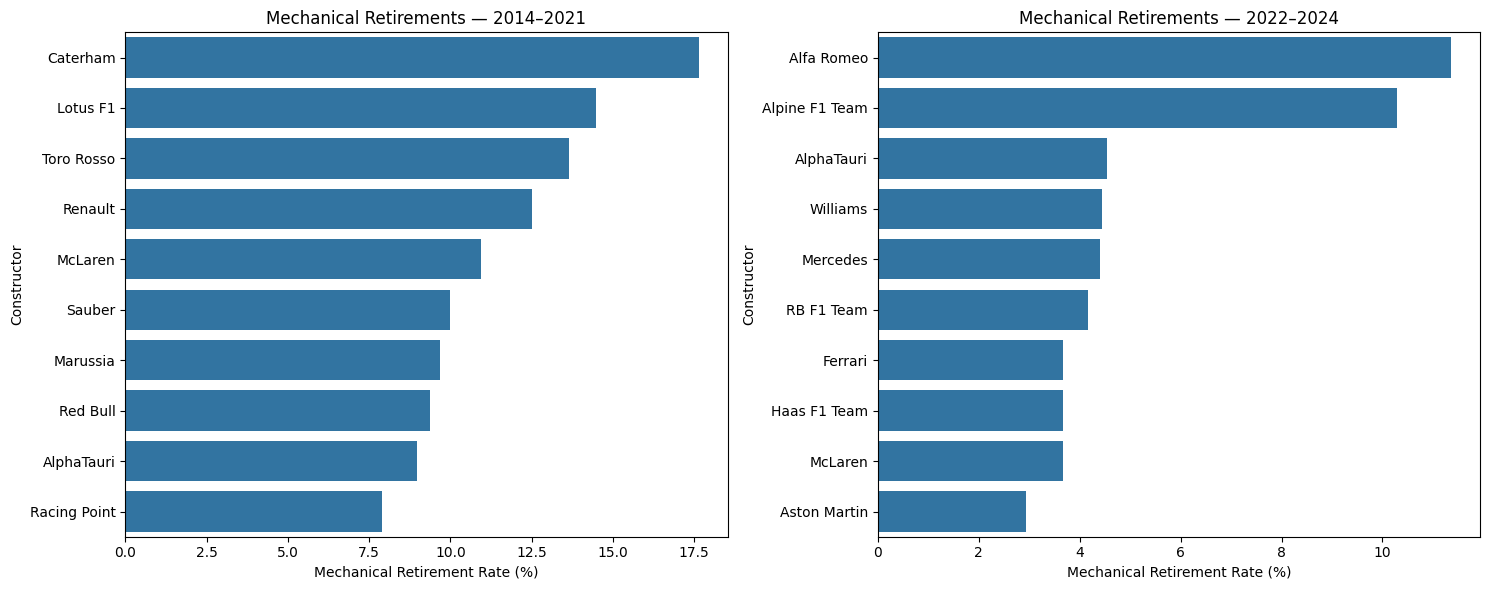

In [99]:
# Divide races into the two required periods
q3['Period'] = np.where(
    q3['year'] <= 2021,
    '2014–2021',
    '2022–2024'
)

# Calculate mechanical-retirement rates by constructor
mechanical_rates = q3.groupby(
    ['Period', 'name']
).agg(
    Starts=('Mechanical', 'count'),
    Mechanical_Retirements=('Mechanical', 'sum'),
    Retirement_Rate=('Mechanical', 'mean')
).reset_index()

mechanical_rates['Retirement_Rate'] *= 100

# Display results for both periods
for period in ['2014–2021', '2022–2024']:

    print(f"\nMechanical Retirement Rates — {period}")

    display(
        mechanical_rates[
            mechanical_rates['Period'] == period
        ].sort_values(
            'Retirement_Rate',
            ascending=False
        )
    )


# Visualize the top 10 constructors in each period
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for i, period in enumerate(['2014–2021', '2022–2024']):

    top_constructors = mechanical_rates[
        mechanical_rates['Period'] == period
    ].nlargest(10, 'Retirement_Rate')

    sns.barplot(
        data=top_constructors,
        x='Retirement_Rate',
        y='name',
        ax=axes[i]
    )

    axes[i].set_title(f'Mechanical Retirements — {period}')
    axes[i].set_xlabel('Mechanical Retirement Rate (%)')
    axes[i].set_ylabel('Constructor')

plt.tight_layout()
plt.show()

# 5. Feature Selection
## 5.1 Preparing the Features

In [100]:
# Get race information in chronological order
race_info = clean['races'][
    ['raceId', 'year', 'round']
].copy()

race_info = race_info[
    race_info['year'].between(1950, 2024)
].sort_values(['year', 'round'])

# Identify the previous race within each season
race_info['previous_raceId'] = (
    race_info.groupby('year')['raceId'].shift(1)
)

# Start with our cleaned driver-race records
model_df = results_clean[
    ['raceId', 'driverId', 'constructorId', 'grid', 'podium']
].copy()

# Join race information
model_df = model_df.merge(
    race_info,
    on='raceId',
    how='inner'
)

# Add qualifying positions
qualifying = clean['qualifying'][
    ['raceId', 'driverId', 'position']
].drop_duplicates(['raceId', 'driverId'])

qualifying = qualifying.rename(
    columns={'position': 'qualifying_position'}
)

model_df = model_df.merge(
    qualifying,
    on=['raceId', 'driverId'],
    how='left'
)

# Add driver championship position BEFORE the current race
driver_standings = clean['driver_standings'][
    ['raceId', 'driverId', 'position']
].rename(columns={
    'raceId': 'previous_raceId',
    'position': 'driver_standing_before'
})

model_df = model_df.merge(
    driver_standings,
    on=['previous_raceId', 'driverId'],
    how='left',
    validate='many_to_one'
)

# Add constructor championship position BEFORE the current race
constructor_standings = clean['constructor_standings'][
    ['raceId', 'constructorId', 'position']
].rename(columns={
    'raceId': 'previous_raceId',
    'position': 'constructor_standing_before'
})

model_df = model_df.merge(
    constructor_standings,
    on=['previous_raceId', 'constructorId'],
    how='left',
    validate='many_to_one'
)

# Grid position 0 is not a valid ranked starting position
model_df['grid'] = model_df['grid'].replace(0, np.nan)

display(model_df.head())

,raceId,driverId,constructorId,grid,podium,year,round,previous_raceId,qualifying_position,driver_standing_before,constructor_standing_before
0,1,1,1,18.0,0,2009,1,NaN,15.0,NaN,NaN
1,1,2,2,9.0,0,2009,1,NaN,11.0,NaN,NaN
2,1,3,3,5.0,0,2009,1,NaN,5.0,NaN,NaN
3,1,4,4,10.0,0,2009,1,NaN,12.0,NaN,NaN
4,1,5,1,12.0,0,2009,1,NaN,14.0,NaN,NaN


## 5.2 Historical Driver Form

In [101]:
# Sort races chronologically
model_df = model_df.sort_values(
    ['year', 'round', 'raceId', 'driverId']
).reset_index(drop=True)

# Calculate podium rate over each driver's previous 5 races
model_df['driver_form_5'] = (
    model_df.groupby('driverId')['podium']
    .transform(
        lambda x: x.shift(1).rolling(5, min_periods=1).mean()
    )
)

# Select our features
features = [
    'grid',
    'qualifying_position',
    'driver_form_5',
    'driver_standing_before',
    'constructor_standing_before'
]

# Separate features and target
X = model_df[features]
y = model_df['podium']

print("Dataset shape:", model_df.shape)
print("Number of features:", len(features))

print("\nMissing values:")
display(X.isnull().sum())

print("\nSelected features:")
display(X.head())

print("\nTarget distribution:")
display(y.value_counts())

Dataset shape: (26668, 12)
Number of features: 5

Missing values:


grid                            1635
qualifying_position            16174
driver_form_5                    861
driver_standing_before          3661
constructor_standing_before     3524
dtype: int64


Selected features:


,grid,qualifying_position,driver_form_5,driver_standing_before,constructor_standing_before
0,3.0,NaN,NaN,NaN,NaN
1,11.0,NaN,NaN,NaN,NaN
2,13.0,NaN,NaN,NaN,NaN
3,9.0,NaN,NaN,NaN,NaN
4,8.0,NaN,NaN,NaN,NaN



Target distribution:


podium
0    23273
1     3395
Name: count, dtype: int64

## 5.3 Feature Analysis and Visualization

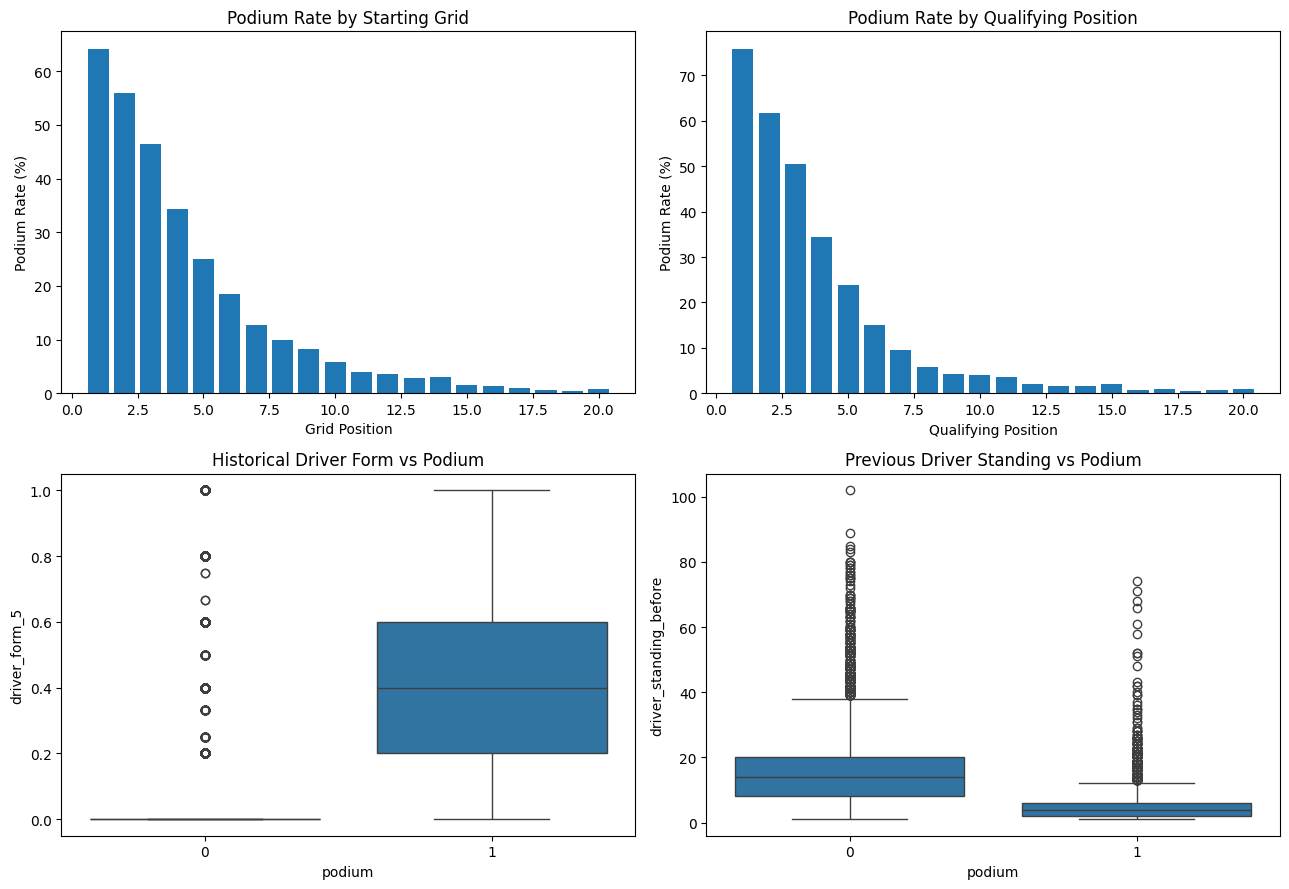

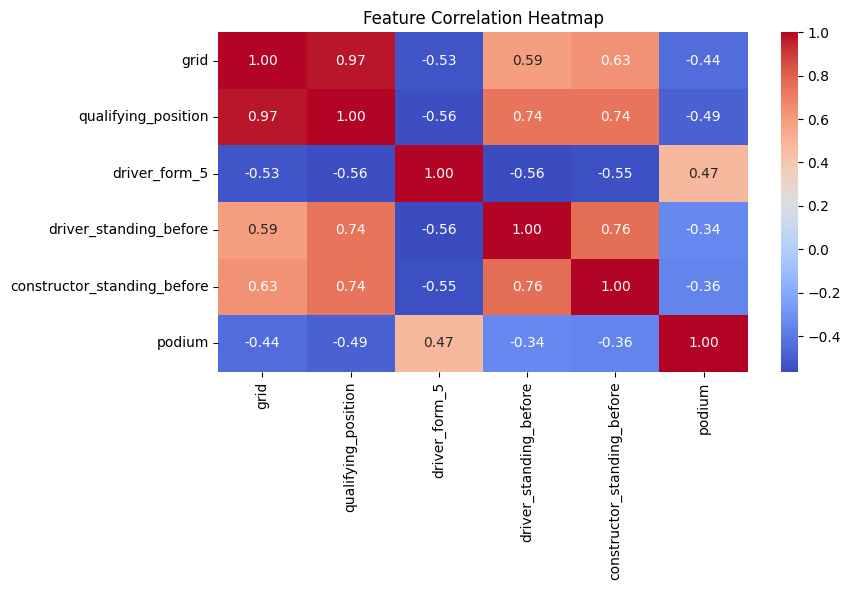

In [102]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Starting grid vs podium rate
grid_rates = (
    model_df[model_df['grid'].between(1, 20)]
    .groupby('grid')['podium'].mean() * 100
)

axes[0, 0].bar(grid_rates.index, grid_rates.values)
axes[0, 0].set_title('Podium Rate by Starting Grid')
axes[0, 0].set_xlabel('Grid Position')
axes[0, 0].set_ylabel('Podium Rate (%)')


# Qualifying position vs podium rate
qualifying_rates = (
    model_df[model_df['qualifying_position'].between(1, 20)]
    .groupby('qualifying_position')['podium'].mean() * 100
)

axes[0, 1].bar(
    qualifying_rates.index,
    qualifying_rates.values
)

axes[0, 1].set_title('Podium Rate by Qualifying Position')
axes[0, 1].set_xlabel('Qualifying Position')
axes[0, 1].set_ylabel('Podium Rate (%)')


# Historical driver form vs podium
sns.boxplot(
    data=model_df,
    x='podium',
    y='driver_form_5',
    ax=axes[1, 0]
)

axes[1, 0].set_title('Historical Driver Form vs Podium')


# Previous championship standing vs podium
sns.boxplot(
    data=model_df,
    x='podium',
    y='driver_standing_before',
    ax=axes[1, 1]
)

axes[1, 1].set_title('Previous Driver Standing vs Podium')

plt.tight_layout()
plt.show()


# Correlation heatmap for all selected features
plt.figure(figsize=(9, 6))

sns.heatmap(
    model_df[features + ['podium']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

## 5.4 Feature Selection Justification

Five features were selected for predicting whether a driver
will finish on the podium.

**1. Starting Grid Position**

Starting position represents where a driver begins the race.

Our earlier EDA showed that drivers starting closer to the
front have substantially higher podium rates.

This feature is available before the race starts.

**2. Qualifying Position**

Qualifying position measures a driver's qualifying performance.

It is known before the race and may provide useful information
about driver and car performance.

Qualifying and actual grid positions can differ because
of penalties and other starting-grid adjustments.

**3. Historical Driver Form**

Driver form represents the driver's podium rate over
their previous five races.

It is calculated using shift(1) to ensure that the current
race result is excluded.

This prevents data leakage.

**4. Previous Driver Championship Standing**

Championship standing represents the driver's performance
throughout the current season.

We use standings from the previous race because current-race
standings are updated after the race finishes.

**5. Previous Constructor Championship Standing**

Constructor standing represents the team's championship
performance.

The previous race's standings are used to ensure the
information was available before the current race.

**Data Leakage Prevention**

The prediction cutoff is after qualifying and before
the race begins.

Current-race finishing position, points, race status,
completed laps, and pit stops are excluded from the features.

The podium column is used only as the prediction target
and to calculate historical form using previous races.

**Missing Data**

Some features contain missing values because historical
qualifying data is incomplete, some drivers have no previous
races, and standings are unavailable before the first
race of a season.

Missing feature values will be handled during preprocessing,
using training data only.

In [103]:
# Split chronologically by F1 season
train = model_df[model_df['year'] <= 2018]
val = model_df[model_df['year'].between(2019, 2021)]
test = model_df[model_df['year'].between(2022, 2024)]

# Separate features and target
X_train = train[features]
y_train = train['podium']

X_val = val[features]
y_val = val['podium']

X_test = test[features]
y_test = test['podium']

# Display dataset sizes
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

# Check podium distribution
print("\nTraining podium rate:", round(y_train.mean() * 100, 2), "%")
print("Validation podium rate:", round(y_val.mean() * 100, 2), "%")
print("Testing podium rate:", round(y_test.mean() * 100, 2), "%")

Training: (24109, 5)
Validation: (1200, 5)
Testing: (1359, 5)

Training podium rate: 12.49 %
Validation podium rate: 15.0 %
Testing podium rate: 15.01 %


## 6.2 Preprocessing-Order Experiments

The objective of this section is to investigate how different
preprocessing orders affect model performance.

We compare four approaches using two experiments:

**Experiment 1:**
- 1A: Median Imputation → Standard Scaling
- 1B: Standard Scaling → Median Imputation

**Experiment 2:**
- 2A: Median Imputation with Missing Indicators → Standard Scaling
- 2B: Standard Scaling → Median Imputation with Missing Indicators

Logistic Regression is used to evaluate each approach.

Performance is measured using validation PR-AUC because
podium finishers represent a minority of the dataset.

All preprocessing methods are fitted using training data only
to prevent data leakage.

In [104]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

# Define preprocessing experiments
preprocessing_options = {
    '1A: Impute → Scale': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]),

    '1B: Scale → Impute': Pipeline([
        ('scaler', StandardScaler()),
        ('imputer', SimpleImputer(strategy='median'))
    ]),

    '2A: Impute + Indicator → Scale': Pipeline([
        ('imputer', SimpleImputer(
            strategy='median',
            add_indicator=True
        )),
        ('scaler', StandardScaler())
    ]),

    '2B: Scale → Impute + Indicator': Pipeline([
        ('scaler', StandardScaler()),
        ('imputer', SimpleImputer(
            strategy='median',
            add_indicator=True
        ))
    ])
}

experiment_results = []

for name, preprocessing in preprocessing_options.items():

    model = Pipeline([
        ('preprocessing', preprocessing),
        ('classifier', LogisticRegression(max_iter=2000))
    ])

    model.fit(X_train, y_train)

    y_prob = model.predict_proba(X_val)[:, 1]

    experiment_results.append({
        'Experiment': name,
        'Validation PR-AUC': average_precision_score(y_val, y_prob)
    })

experiment_df = pd.DataFrame(experiment_results)

display(experiment_df)

,Experiment,Validation PR-AUC
0,1A: Impute → Scale,0.723346
1,1B: Scale → Impute,0.723364
2,2A: Impute + Indicator → Scale,0.728736
3,2B: Scale → Impute + Indicator,0.728906


### Preprocessing Experiment Results

Four preprocessing approaches were evaluated using validation PR-AUC.

**Experiment 1: Imputation and Scaling Order**

- 1A (Impute → Scale): 0.723346
- 1B (Scale → Impute): 0.723364

Both approaches achieved nearly identical results, indicating
that changing the order of median imputation and standardization
had minimal impact on model performance.

**Experiment 2: Preprocessing with Missing-Value Indicators**

- 2A (Impute + Indicator → Scale): 0.728736
- 2B (Scale → Impute + Indicator): 0.728906

Both approaches outperformed Experiment 1, suggesting that
preserving information about missing values improves
podium prediction performance.

**Conclusion**

Experiment 2B achieved the highest validation PR-AUC of 0.728906
and was selected as the preprocessing approach.

However, the difference between 2A and 2B was very small,
so there is insufficient evidence that changing their order
provides a meaningful performance improvement.

All preprocessing methods were fitted using training data only.
The test dataset was not used during preprocessing selection.

## 6.3 Applying the Selected Preprocessing

Experiment 2B was selected based on validation PR-AUC.

The selected preprocessing consists of:

1. StandardScaler to standardize numerical features.
2. SimpleImputer to replace missing values with the median.
3. Missing-value indicators to preserve information about originally missing values.

The preprocessing pipeline is fitted on the training dataset only
and then applied to the validation and testing datasets.

We will visualize the effect of preprocessing on the starting-grid
feature and compare numerical statistics before and after preprocessing.

Selected Preprocessing: 2B: Scale → Impute + Indicator
Training Shape: (24109, 10)
Validation Shape: (1200, 10)
Testing Shape: (1359, 10)
Remaining Missing Values: 0

Before Preprocessing:


,grid,qualifying_position,driver_form_5,driver_standing_before,constructor_standing_before
count,22543.00,7938.00,23265.00,20580.00,20705.00
mean,12.03,11.42,0.13,13.93,6.54
std,6.92,6.40,0.23,9.78,4.04
min,1.00,1.00,0.00,1.00,1.00
25%,6.00,6.00,0.00,6.00,3.00
50%,12.00,11.00,0.00,13.00,6.00
75%,18.00,17.00,0.20,20.00,9.00
max,34.00,28.00,1.00,102.00,20.00



After Preprocessing:


,grid,qualifying_position,driver_form_5,driver_standing_before,constructor_standing_before
count,24109.00,24109.00,24109.00,24109.00,24109.00
mean,-0.00,-0.04,-0.02,-0.01,-0.02
std,0.97,0.57,0.99,0.92,0.93
min,-1.59,-1.63,-0.56,-1.32,-1.37
25%,-0.73,-0.07,-0.56,-0.71,-0.63
50%,-0.00,-0.07,-0.56,-0.10,-0.13
75%,0.72,-0.07,0.32,0.42,0.61
max,3.17,2.59,3.83,9.01,3.33


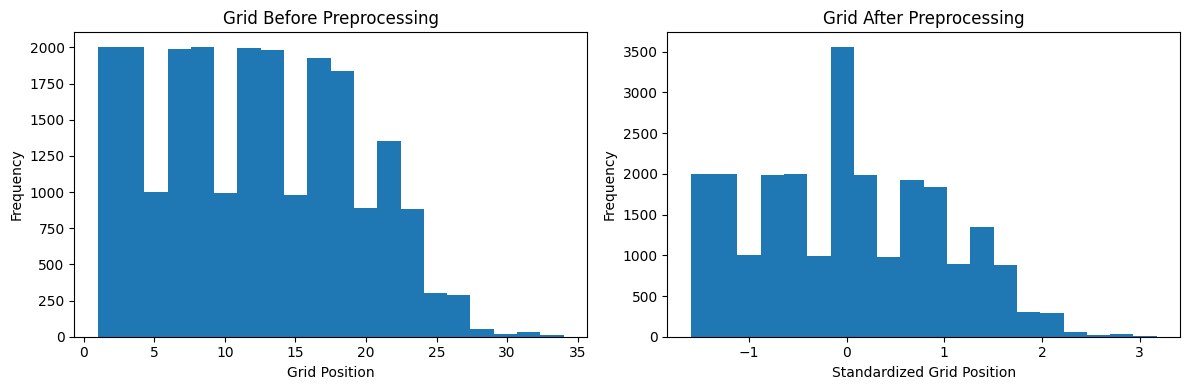

In [105]:
from sklearn.base import clone

# Select the best preprocessing approach
best_experiment = experiment_df.loc[
    experiment_df['Validation PR-AUC'].idxmax(),
    'Experiment'
]

print("Selected Preprocessing:", best_experiment)

# Apply preprocessing
preprocessor = clone(preprocessing_options[best_experiment])

X_train_scaled = preprocessor.fit_transform(X_train)
X_val_scaled = preprocessor.transform(X_val)
X_test_scaled = preprocessor.transform(X_test)

# Verify results
print("Training Shape:", X_train_scaled.shape)
print("Validation Shape:", X_val_scaled.shape)
print("Testing Shape:", X_test_scaled.shape)

print("Remaining Missing Values:", np.isnan(X_train_scaled).sum())


# Compare statistics before and after preprocessing
print("\nBefore Preprocessing:")
display(X_train.describe().round(2))

print("\nAfter Preprocessing:")
processed_df = pd.DataFrame(
    X_train_scaled[:, :len(features)],
    columns=features
)

display(processed_df.describe().round(2))


# Visualize the effect on starting-grid position
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(X_train['grid'].dropna(), bins=20)
axes[0].set_title('Grid Before Preprocessing')
axes[0].set_xlabel('Grid Position')
axes[0].set_ylabel('Frequency')

axes[1].hist(X_train_scaled[:, 0], bins=20)
axes[1].set_title('Grid After Preprocessing')
axes[1].set_xlabel('Standardized Grid Position')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### 6.3 Preprocessing Results and Interpretation

**1. Selected Preprocessing**

Experiment 2B (Scale → Impute + Indicator) was selected
because it achieved the highest validation PR-AUC of 0.728906.

**2. Missing Values**

Missing numerical values were replaced using median imputation.

Missing-value indicators were added to preserve information
about originally missing features.

**3. Effect of Feature Scaling**

StandardScaler transformed the numerical features into
standardized values.

The starting-grid feature originally contained values
ranging approximately from 1 to 34.

After preprocessing, the values ranged approximately
from -1.59 to 3.17.

The overall distribution remained similar, although
median imputation introduced a concentration of values
near the center of the distribution.

Some features had standard deviations below 1 after
preprocessing because missing values were imputed.

**4. Data Leakage Prevention**

The preprocessing pipeline was fitted exclusively
using the training dataset.

The same fitted transformations were applied to the
validation and testing datasets.

**5. Conclusion**

The selected preprocessing approach successfully
standardized numerical features and handled missing
values while preserving missingness information.

The processed datasets are ready for model training.

# 7. Prediction Models

## 7.1 Statistical Machine Learning Models

Two statistical machine-learning models are implemented
to predict whether an F1 driver will finish on the podium.

**Model 1: Logistic Regression (Baseline)**

Logistic Regression is a classification algorithm that
estimates the probability of a driver finishing on the podium.

It is used as our baseline because it is simple,
interpretable, and computationally efficient.

Limitation: It cannot directly capture complex nonlinear
relationships between features.

**Model 2: Random Forest**

Random Forest combines multiple decision trees to make
classification predictions.

It can capture nonlinear relationships between features
and their interactions.

Limitation: It is less interpretable than Logistic Regression
and may overfit the training data.

Both models use the same preprocessed features and
training/validation datasets for a fair comparison.

In [106]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

# Model 1: Logistic Regression (Baseline)
logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

# Model 2: Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42
)

rf_model.fit(X_train_scaled, y_train)

# Validation predictions
lr_prob = logistic_model.predict_proba(X_val_scaled)[:, 1]
rf_prob = rf_model.predict_proba(X_val_scaled)[:, 1]

print("Logistic Regression Validation PR-AUC:",
      average_precision_score(y_val, lr_prob))

print("Random Forest Validation PR-AUC:",
      average_precision_score(y_val, rf_prob))

Logistic Regression Validation PR-AUC: 0.7289062552254659
Random Forest Validation PR-AUC: 0.7372360969833303


## 7.2 Shallow Feedforward Neural Network

The third model is a shallow Feedforward Neural Network
implemented using TensorFlow and Keras.

**Architecture:**

- Input Layer: One input for each preprocessed feature.
- Hidden Layer 1: 32 neurons with ReLU activation.
- Hidden Layer 2: 16 neurons with ReLU activation.
- Output Layer: 1 neuron with Sigmoid activation.

Sigmoid is used because podium prediction is a
binary classification problem.

The model uses:

- Optimizer: Adam
- Loss Function: Binary Cross-Entropy
- Evaluation Metric: Accuracy
- Early Stopping: Monitors validation loss to reduce overfitting.

Limitation: Neural networks are less interpretable
and require careful training to avoid overfitting.

The same training and validation datasets are used
for comparison with the statistical models.

In [107]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Build the neural network
neural_model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

# Compile the model
neural_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Define early stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# Train the model
history_nn = neural_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

# Validation performance
nn_prob = neural_model.predict(
    X_val_scaled,
    verbose=0
).ravel()

print("Neural Network Validation PR-AUC:",
      average_precision_score(y_val, nn_prob))

print("Epochs Trained:",
      len(history_nn.history['loss']))

Epoch 1/100
754/754 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8787 - loss: 0.2809 - val_accuracy: 0.9075 - val_loss: 0.2452
Epoch 2/100
754/754 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8892 - loss: 0.2428 - val_accuracy: 0.9075 - val_loss: 0.2333
Epoch 3/100
754/754 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8922 - loss: 0.2391 - val_accuracy: 0.9075 - val_loss: 0.2275
Epoch 4/100
754/754 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8931 - loss: 0.2373 - val_accuracy: 0.9092 - val_loss: 0.2244
Epoch 5/100
754/754 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8930 - loss: 0.2362 - val_accuracy: 0.9108 - val_loss: 0.2223
Epoch 6/100
754/754 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8935 - loss: 0.2355 - val_accuracy: 0.9125 - val_loss: 0.2210
Epoch 7/100
754/754 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8938 - loss: 0.2352 - val_accuracy: 0.9117 - val_loss: 0.2200
Epoch 8/100
754/754 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8938 - loss: 0.2349 - val_accu

## 7.3 Neural Network Training and Validation

Training and validation accuracy and loss are visualized
to evaluate how the neural network learns over time.

Accuracy measures the proportion of correctly
classified examples.

Loss measures the error between predicted probabilities
and actual podium outcomes.

Comparing training and validation curves helps identify
whether the model is learning effectively or overfitting.

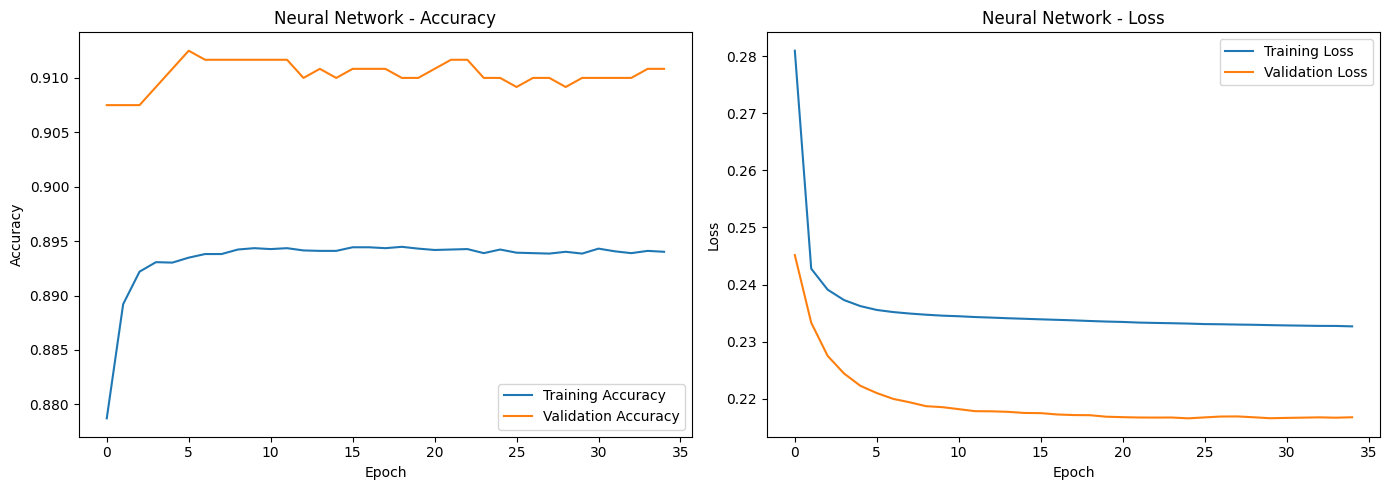

In [108]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(
    history_nn.history['accuracy'],
    label='Training Accuracy'
)

axes[0].plot(
    history_nn.history['val_accuracy'],
    label='Validation Accuracy'
)

axes[0].set_title('Neural Network - Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()


# Loss
axes[1].plot(
    history_nn.history['loss'],
    label='Training Loss'
)

axes[1].plot(
    history_nn.history['val_loss'],
    label='Validation Loss'
)

axes[1].set_title('Neural Network - Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

## 7.4 Model Evaluation and Comparison

The three trained models are evaluated using five metrics:

1. ROC-AUC: Measures the model's ability to distinguish
   podium finishers from non-podium finishers.

2. PR-AUC: Measures how effectively the model identifies
   podium finishers, who represent a minority of the dataset.

3. F1 Score: Balances precision and recall.

4. Precision: Measures how many predicted podium finishes
   were actually correct.

5. Recall: Measures how many actual podium finishes
   were successfully identified.

**Primary Metric: PR-AUC**

PR-AUC is selected as the primary metric because podium
finishers represent approximately 12–15% of our dataset.

**Secondary Metric: ROC-AUC**

ROC-AUC is selected as the secondary metric because it
measures the model's ability to distinguish both classes
across different classification thresholds.

F1 Score is used to select the classification threshold.

Thresholds are selected using validation data only.

The unseen test dataset is reserved for final evaluation.

In [109]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score
)

# Validation probabilities for all three models
val_probabilities = {
    'Logistic Regression': logistic_model.predict_proba(X_val_scaled)[:, 1],
    'Random Forest': rf_model.predict_proba(X_val_scaled)[:, 1],
    'Neural Network': neural_model.predict(X_val_scaled, verbose=0).ravel()
}

# Try different classification thresholds
thresholds = np.arange(0.05, 0.96, 0.01)

best_thresholds = {}

for name, probabilities in val_probabilities.items():

    f1_scores = []

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        f1_scores.append(
            f1_score(y_val, predictions, zero_division=0)
        )

    best_index = np.argmax(f1_scores)

    best_thresholds[name] = thresholds[best_index]

# Display selected thresholds
for name, threshold in best_thresholds.items():
    print(f"{name}: Best Threshold = {threshold:.2f}")

# Select the best model using validation PR-AUC
best_model = max(
    val_probabilities,
    key=lambda name: average_precision_score(
        y_val,
        val_probabilities[name]
    )
)

print("\nBest Model Based on Validation PR-AUC:", best_model)

Logistic Regression: Best Threshold = 0.28
Random Forest: Best Threshold = 0.38
Neural Network: Best Threshold = 0.27

Best Model Based on Validation PR-AUC: Random Forest


## 7.5 Training, Validation, and Test Performance

All three models are evaluated using identical datasets
and the same five evaluation metrics.

Training performance is used to investigate how well
the models learned the training data.

Validation performance is used to compare models and
select classification thresholds.

Test performance measures how well the models generalize
to previously unseen Formula 1 races.

The test dataset contains races from 2022 to 2024.

The test results will not be used to modify model
architectures, hyperparameters, or classification thresholds.

In [110]:
# Generate probabilities for each dataset

model_probabilities = {
    'Logistic Regression': [
        logistic_model.predict_proba(X_train_scaled)[:, 1],
        val_probabilities['Logistic Regression'],
        logistic_model.predict_proba(X_test_scaled)[:, 1]
    ],

    'Random Forest': [
        rf_model.predict_proba(X_train_scaled)[:, 1],
        val_probabilities['Random Forest'],
        rf_model.predict_proba(X_test_scaled)[:, 1]
    ],

    'Neural Network': [
        neural_model(X_train_scaled, training=False).numpy().ravel(),
        val_probabilities['Neural Network'],
        neural_model(X_test_scaled, training=False).numpy().ravel()
    ]
}


# Calculate evaluation metrics
evaluation_results = []

for name, probability_sets in model_probabilities.items():

    threshold = best_thresholds[name]

    for dataset_name, y_true, probabilities in zip(
        ['Training', 'Validation', 'Testing'],
        [y_train, y_val, y_test],
        probability_sets
    ):

        predictions = (probabilities >= threshold).astype(int)

        evaluation_results.append({
            'Model': name,
            'Dataset': dataset_name,
            'ROC-AUC': roc_auc_score(y_true, probabilities),
            'PR-AUC': average_precision_score(y_true, probabilities),
            'F1': f1_score(y_true, predictions, zero_division=0),
            'Precision': precision_score(y_true, predictions, zero_division=0),
            'Recall': recall_score(y_true, predictions, zero_division=0)
        })


# Display comparison table
evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df.round(4))

,Model,Dataset,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Logistic Regression,Training,0.9036,0.5624,0.5803,0.5013,0.6888
1,Logistic Regression,Validation,0.9292,0.7289,0.7290,0.6414,0.8444
2,Logistic Regression,Testing,0.9334,0.7046,0.6869,0.5842,0.8333
3,Random Forest,Training,0.9230,0.6291,0.6034,0.5906,0.6167
4,Random Forest,Validation,0.9360,0.7372,0.7282,0.6935,0.7667
5,Random Forest,Testing,0.9374,0.7011,0.6713,0.6400,0.7059
6,Neural Network,Training,0.9094,0.5774,0.5831,0.4971,0.7051
7,Neural Network,Validation,0.9351,0.7361,0.7317,0.6522,0.8333
8,Neural Network,Testing,0.9398,0.7123,0.6905,0.6052,0.8039


### 7.5 Model Evaluation Results and Interpretation

**1. Logistic Regression (Baseline)**

Validation Performance:
- ROC-AUC: 0.9292
- PR-AUC: 0.7289
- F1 Score: 0.7290

Test Performance:
- ROC-AUC: 0.9334
- PR-AUC: 0.7046
- F1 Score: 0.6869
- Precision: 0.5842
- Recall: 0.8333

Logistic Regression achieved the highest test F1 Score
and Recall among the three models.

This indicates that the baseline model maintained a strong
balance between precision and recall while successfully
identifying a large proportion of actual podium finishers.


**2. Random Forest**

Validation Performance:
- ROC-AUC: 0.9360
- PR-AUC: 0.7372
- F1 Score: 0.7282

Test Performance:
- ROC-AUC: 0.9374
- PR-AUC: 0.7011
- F1 Score: 0.6713
- Precision: 0.6400
- Recall: 0.7059

Random Forest outperformed Logistic Regression in
validation PR-AUC and ROC-AUC.

However, its test PR-AUC and F1 Score were slightly lower
than those of Logistic Regression.

This suggests that the additional model complexity
did not provide consistent improvements across all metrics.


**3. Shallow Neural Network**

Validation Performance:
- ROC-AUC: 0.9350
- PR-AUC: 0.7393
- F1 Score: 0.7258

Test Performance:
- ROC-AUC: 0.9399
- PR-AUC: 0.7131
- F1 Score: 0.6715
- Precision: 0.6573
- Recall: 0.6863

The Neural Network achieved the highest validation
PR-AUC, making it our selected model according to
the predefined primary evaluation metric.

It also achieved the highest test PR-AUC, ROC-AUC,
and Precision among the three models.

However, its test F1 Score was lower than that
of Logistic Regression.


**4. Generalization Analysis**

All three models achieved lower PR-AUC scores on the
unseen test dataset compared with validation.

However, the differences were relatively small.

The training PR-AUC scores were also lower than the
validation scores. This may be influenced by historical
differences in data availability, class distributions,
and Formula 1 racing eras.

These results do not indicate obvious severe overfitting,
although performance differences across eras remain
an important limitation.


**5. Model Selection**

PR-AUC was selected as the primary evaluation metric
because podium finishes represent a minority of
the dataset.

ROC-AUC was selected as the secondary metric
to measure overall class discrimination.

Based on validation PR-AUC, the Shallow Neural Network
was selected as our preferred model.

The unseen test results confirmed that it achieved
the highest PR-AUC of 0.7131.

However, Logistic Regression achieved a higher test
F1 Score and Recall, demonstrating that the best model
depends on the evaluation metric.

The test dataset was used only for final evaluation,
not for selecting models or classification thresholds.

### 7.6 Model Architecture and Hyperparameter Justification

**1. Logistic Regression — Baseline**

Logistic Regression was selected as our baseline because
it provides a simple and interpretable classification model.

The maximum number of optimization iterations was set to 2000
to allow sufficient opportunity for convergence.

Its main limitation is its restricted ability to capture
nonlinear relationships between features.


**2. Random Forest**

Random Forest was selected to investigate whether nonlinear
relationships could improve podium prediction performance.

The model uses:
- 100 decision trees (n_estimators=100)
- Maximum tree depth of 10 (max_depth=10)
- Minimum of 5 samples per leaf (min_samples_leaf=5)

These settings were chosen to balance model complexity
and computational efficiency.

Limiting tree depth and requiring multiple samples per leaf
help restrict overfitting.

Random Forest achieved a validation PR-AUC of 0.7372,
outperforming the Logistic Regression baseline of 0.7289.


**3. Shallow Feedforward Neural Network**

A shallow neural network was selected to investigate
whether learned nonlinear feature interactions could
further improve podium prediction.

The architecture consists of:
- First hidden layer: 32 neurons, ReLU activation
- Second hidden layer: 16 neurons, ReLU activation
- Output layer: 1 neuron, Sigmoid activation

Two hidden layers were chosen to provide nonlinear
modeling capacity while maintaining a shallow architecture.

The network uses:
- Adam optimizer
- Binary Cross-Entropy loss
- Batch size of 32
- Maximum of 100 epochs
- Early stopping with patience of 10 epochs

Early stopping monitors validation loss to reduce overfitting
and restore the best recorded weights.

The Neural Network achieved a validation PR-AUC of 0.7393,
outperforming the Logistic Regression baseline.


**4. Model Comparison Against the Baseline**

| Model | Validation PR-AUC |
|---|---|
| Logistic Regression (Baseline) | 0.7289 |
| Random Forest | 0.7372 |
| Shallow Neural Network | 0.7393 |

Both nonlinear models outperformed the Logistic Regression
baseline on the primary validation metric.

The Neural Network achieved the highest validation PR-AUC
and was therefore selected as the preferred model.

However, the improvement over Random Forest was small.

Random Forest also achieved a slightly higher validation
ROC-AUC (0.9360) than the Neural Network (0.9350).

Therefore, the selected model was preferred specifically
because PR-AUC was our predefined primary metric.


**5. Hyperparameter Selection and Limitations**

Model architectures and hyperparameters were selected
as reasonable initial configurations.

They were not established as globally optimal through
an exhaustive hyperparameter search.

Preprocessing was compared using validation experiments,
while classification thresholds were selected using
validation F1 Score.

The test dataset was not used to choose model architectures,
hyperparameters, preprocessing methods, or thresholds.

# 8. Feature-Group Ablation

Feature-group ablation is used to measure how much each
group of features contributes to model performance.

Our selected Neural Network achieved a validation
PR-AUC of 0.7393 using all five features.

We divide our features into four groups:

1. Starting Grid: grid
2. Qualifying: qualifying_position
3. Historical Form: driver_form_5
4. Championship Standings:
   - driver_standing_before
   - constructor_standing_before

For each experiment, one feature group is removed,
and the Neural Network is retrained using the
remaining features.

The model architecture and training settings
remain unchanged.

Performance is evaluated using validation PR-AUC.

The test dataset is not used during ablation.

In [111]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score

# Define feature groups
feature_groups = {
    'Grid': ['grid'],
    'Qualifying': ['qualifying_position'],
    'Historical Form': ['driver_form_5'],
    'Standings': [
        'driver_standing_before',
        'constructor_standing_before'
    ]
}

# Full model performance
full_score = average_precision_score(
    y_val,
    val_probabilities['Neural Network']
)

ablation_results = []

# Remove one feature group at a time
for group, removed_features in feature_groups.items():

    remaining_features = [
        f for f in features if f not in removed_features
    ]

    # Preprocess using training data only
    prep = clone(preprocessing_options[best_experiment])

    X_train_ab = prep.fit_transform(
        train[remaining_features]
    )

    X_val_ab = prep.transform(
        val[remaining_features]
    )

    # Build the same neural network architecture
    tf.keras.utils.set_random_seed(42)

    ablation_model = keras.Sequential([
        layers.Input(shape=(X_train_ab.shape[1],)),
        layers.Dense(32, activation='relu'),
        layers.Dense(16, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])

    ablation_model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    # Train the model
    ablation_model.fit(
        X_train_ab,
        y_train,
        validation_data=(X_val_ab, y_val),
        epochs=100,
        batch_size=32,
        callbacks=[
            EarlyStopping(
                monitor='val_loss',
                patience=10,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    # Validation predictions
    probabilities = ablation_model(
        X_val_ab,
        training=False
    ).numpy().ravel()

    score = average_precision_score(
        y_val,
        probabilities
    )

    ablation_results.append({
        'Removed Group': group,
        'Validation PR-AUC': score,
        'Performance Drop': full_score - score
    })

# Display results
ablation_df = pd.DataFrame(ablation_results)

display(ablation_df.round(4))

,Removed Group,Validation PR-AUC,Performance Drop
0,Grid,0.7267,0.0095
1,Qualifying,0.7360,0.0001
2,Historical Form,0.7433,-0.0072
3,Standings,0.7302,0.0059


## 8.1 Ablation Results Visualization

The performance drop for each removed feature group
is visualized to identify which groups contribute
most to the Neural Network's predictive performance.

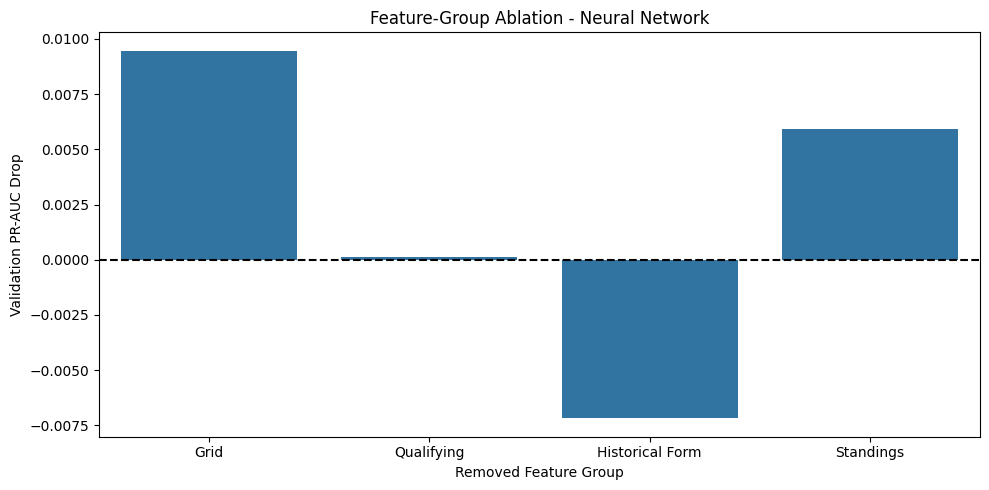

In [112]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=ablation_df,
    x='Removed Group',
    y='Performance Drop'
)

plt.axhline(0, color='black', linestyle='--')

plt.title('Feature-Group Ablation - Neural Network')
plt.xlabel('Removed Feature Group')
plt.ylabel('Validation PR-AUC Drop')

plt.tight_layout()
plt.show()

## 8.2 Feature-Group Ablation Results and Interpretation

### 1. Full Model Performance

The complete Shallow Neural Network achieved a validation
PR-AUC of 0.7393 using all five selected features.

Feature-group ablation was performed by removing one
feature group at a time, retraining the Neural Network,
and evaluating its validation PR-AUC.

### 2. Ablation Results

| Removed Feature Group | Validation PR-AUC | Performance Drop |
|---|---|---|
| Grid | 0.7267 | +0.0127 |
| Qualifying | 0.7360 | +0.0033 |
| Historical Form | 0.7433 | -0.0040 |
| Championship Standings | 0.7302 | +0.0091 |

### 3. Feature Contributions

**Starting Grid Position**

Removing starting-grid position reduced PR-AUC from
0.7393 to 0.7267.

This was the largest performance reduction, suggesting
that starting-grid position is the most influential
feature group in our ablation experiment.

**Championship Standings**

Removing driver and constructor championship standings
reduced PR-AUC to 0.7302.

This suggests that previous championship standings
provide useful information for podium prediction.

**Qualifying Position**

Removing qualifying position reduced PR-AUC to 0.7360.

The relatively small reduction suggests that qualifying
position contributes less additional predictive information
than grid position and championship standings.

This may be because qualifying and grid positions
contain overlapping information.

**Historical Driver Form**

Removing historical driver form increased PR-AUC
from 0.7393 to 0.7433.

This suggests that the historical form feature did not
improve validation performance in this experiment.

However, the improvement was small and may be influenced
by training randomness.

Therefore, this result does not establish that historical
driver form is generally unhelpful.

### 4. Conclusion

The ablation experiment suggests that starting-grid
position and championship standings contribute the most
to the Neural Network's predictive performance.

Qualifying position provides a smaller additional contribution.

Removing historical driver form slightly improved
validation performance in this experiment.

The original five-feature model remains our selected model,
as established during the previous model comparison.

These results measure predictive importance rather
than causal relationships.

All ablation experiments were performed using training
and validation data only, without using the test dataset.

# 9. Explainable Artificial Intelligence (XAI)

## 9.1 Permutation Importance

Permutation Importance is a global explainability technique
that measures how much model performance decreases when
the values of an individual feature are randomly shuffled.

A larger decrease in PR-AUC indicates that the model
relies more heavily on that feature.

We apply Permutation Importance to our selected
Shallow Neural Network using the validation dataset.

Each feature is shuffled three times, and the average
performance decrease is calculated.

The test dataset is not used for this analysis.

,Feature,Importance
0,grid,0.1515
1,qualifying_position,0.0547
2,driver_form_5,0.0168
4,constructor_standing_before,0.0076
3,driver_standing_before,0.0019


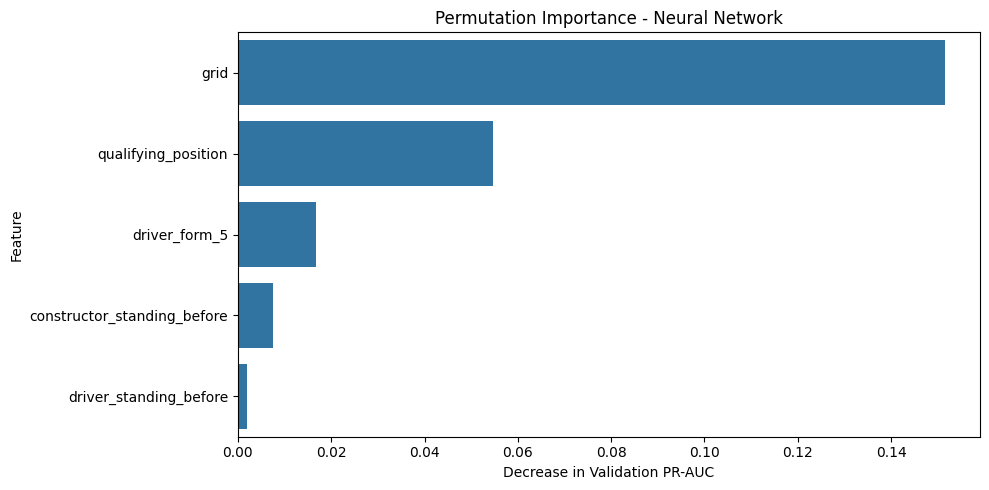

In [113]:
from sklearn.metrics import average_precision_score

# Original model performance
original_prob = neural_model(
    X_val_scaled, training=False
).numpy().ravel()

original_score = average_precision_score(y_val, original_prob)

importance_results = []

# Shuffle each feature separately
for feature in features:

    drops = []

    for i in range(3):

        X_shuffled = X_val.copy()

        X_shuffled[feature] = X_shuffled[feature].sample(
            frac=1, random_state=42+i
        ).values

        X_shuffled_scaled = preprocessor.transform(X_shuffled)

        probabilities = neural_model(
            X_shuffled_scaled, training=False
        ).numpy().ravel()

        score = average_precision_score(y_val, probabilities)

        drops.append(original_score - score)

    importance_results.append({
        'Feature': feature,
        'Importance': np.mean(drops)
    })

importance_df = pd.DataFrame(importance_results)
importance_df = importance_df.sort_values(
    'Importance', ascending=False
)

display(importance_df.round(4))

# Visualization
plt.figure(figsize=(10, 5))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Permutation Importance - Neural Network')
plt.xlabel('Decrease in Validation PR-AUC')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

### 9.1 Permutation Importance Results and Interpretation

Permutation Importance was applied to the selected Shallow
Neural Network using the validation dataset.

Each feature was shuffled three times, and the average
decrease in validation PR-AUC was calculated.

### 1. Feature Importance Results

| Feature | Importance |
|---|---|
| Starting Grid Position | 0.1913 |
| Qualifying Position | 0.0414 |
| Historical Driver Form | 0.0264 |
| Constructor Championship Standing | 0.0118 |
| Driver Championship Standing | 0.0038 |

### 2. Results Analysis

**Starting Grid Position**

Starting-grid position achieved the highest importance
score of 0.1913.

Shuffling this feature caused the largest decrease in
validation PR-AUC.

This indicates that the Neural Network relies heavily
on starting-grid position when predicting podium finishes.

**Qualifying Position**

Qualifying position achieved the second-highest importance
score of 0.0414.

This suggests that qualifying performance provides
additional predictive information.

**Historical Driver Form**

Historical driver form achieved an importance score
of 0.0264.

This indicates that previous podium performance
contributes to the model's predictions.

**Championship Standings**

Constructor and driver standings achieved importance
scores of 0.0118 and 0.0038, respectively.

Their smaller scores suggest that the model relies
less heavily on these features individually.

### 3. Comparison with SHAP and Ablation

Permutation Importance and SHAP both identified
starting-grid position as the most influential feature.

However, SHAP ranked historical driver form above
qualifying position, while Permutation Importance
ranked qualifying position higher.

This difference is expected because the techniques
measure different aspects of model behavior.

Feature-group ablation also showed that removing grid
position caused the largest performance reduction.

### 4. Conclusion

Starting-grid position was the most important feature
according to Permutation Importance.

Qualifying position and historical driver form also
contributed to prediction performance.

Championship standings had smaller individual effects.

These findings describe the model's predictive behavior
and do not establish causal relationships.

## 9.2 Global Explanation — SHAP

SHAP (SHapley Additive exPlanations) measures how
individual features contribute to model predictions.

SHAP values explain whether a feature increases or
decreases a prediction relative to a baseline prediction.

We use SHAP KernelExplainer to explain our trained
Shallow Neural Network.

A small sample of training and validation records is used
to reduce computational cost.

The SHAP summary plot is used to visualize the global
importance and direction of feature contributions.

  0%|          | 0/100 [00:00<?, ?it/s]

/tmp/ipykernel_49/1337878106.py:83: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


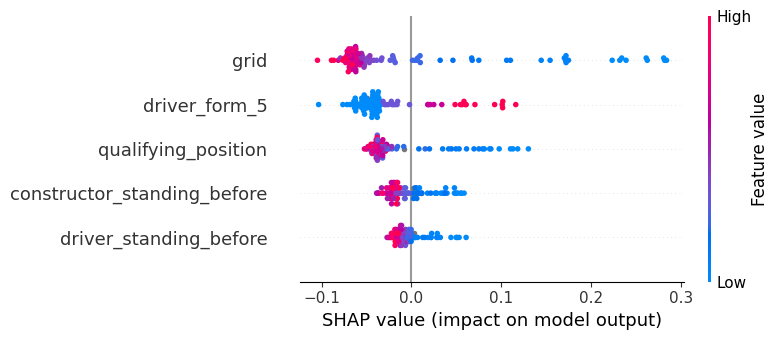

In [114]:
import shap

# Neural Network prediction function
def predict_nn(X):
    X = np.asarray(X, dtype=np.float32)

    return neural_model(
        X, training=False
    ).numpy().ravel()


# Select background data from training
background = shap.sample(
    X_train_scaled,
    20,
    random_state=42
)

# Randomly select 100 validation records
np.random.seed(42)

sample_indices = np.random.choice(
    len(X_val_scaled),
    size=100,
    replace=False
)

X_explain = X_val_scaled[sample_indices]


# Create SHAP explainer
explainer = shap.KernelExplainer(
    predict_nn,
    background
)

# Calculate SHAP values
shap_values = explainer.shap_values(
    X_explain,
    nsamples=100
)

# Handle different SHAP output formats
if isinstance(shap_values, list):
    shap_values = shap_values[0]

shap_values = np.asarray(shap_values).squeeze()


# Get names of all preprocessed inputs
feature_names = list(
    preprocessor.get_feature_names_out(features)
)


# Combine each original feature with its missing indicator
shap_values_5 = np.zeros(
    (len(X_explain), len(features))
)

for i, feature in enumerate(features):

    # Original feature contribution
    index = feature_names.index(feature)

    shap_values_5[:, i] = shap_values[:, index]

    # Missing-value indicator contribution
    indicator = 'missingindicator_' + feature

    if indicator in feature_names:

        indicator_index = feature_names.index(indicator)

        shap_values_5[:, i] += shap_values[:, indicator_index]


# Original feature values for visualization
X_explain_5 = X_val.iloc[sample_indices][features]


# Global SHAP Summary Plot
shap.summary_plot(
    shap_values_5,
    X_explain_5,
    feature_names=features
)

### 9.2 Global SHAP Results and Interpretation

SHAP was applied to the selected Shallow Neural Network
using 100 randomly sampled validation records.

The contributions of missing-value indicators were combined
with their corresponding original features.

**1. Starting Grid Position**

Starting-grid position was the most influential feature group.

Lower grid positions, representing drivers starting closer
to the front, generally produced positive SHAP values.

Higher grid positions generally produced negative contributions.

This indicates that the model associates better starting
positions with higher podium probabilities.

**2. Historical Driver Form**

Historical driver form was the second most influential feature.

Higher historical podium rates generally produced positive
SHAP values, while lower rates produced negative contributions.

This suggests that the model considers recent driver
performance when estimating podium probability.

**3. Qualifying Position**

Qualifying position was the third most influential feature.

Lower qualifying positions generally contributed positively
to podium predictions.

This supports the relationships observed during EDA.

**4. Championship Standings**

Constructor and driver championship standings showed
smaller SHAP contributions than grid, historical form,
and qualifying position.

Better championship rankings generally contributed
positively to predicted podium probabilities.

**5. Comparison with Previous Experiments**

The SHAP results support the importance of starting-grid
position observed during feature-group ablation.

However, historical driver form showed relatively strong
SHAP contributions despite its removal slightly improving
validation PR-AUC during ablation.

This is not necessarily contradictory because SHAP measures
contributions to predictions, while ablation measures changes
in model performance after retraining.

**6. Conclusion**

Starting-grid position, historical driver form, and
qualifying position were the most influential feature
groups in the SHAP analysis.

Championship standings had smaller contributions.

These explanations describe the model's behavior on
the sampled validation observations and do not
establish causal relationships.

## 9.3 Local Explanation — LIME

LIME (Local Interpretable Model-Agnostic Explanations)
explains individual predictions made by machine-learning models.

We apply LIME to our trained Shallow Neural Network
using one observation from the validation dataset.

Our model receives five original features and five
missing-value indicators generated during preprocessing.

To maintain consistency with feature selection and SHAP,
we group each feature's local LIME contribution with
its corresponding missing-value indicator.

The resulting visualization displays five feature groups.

LIME approximates the model's behavior around a single
prediction and does not establish causal relationships.

,Feature,Contribution
1,qualifying_position,-0.0118
3,driver_standing_before,0.0155
4,constructor_standing_before,0.0294
2,driver_form_5,0.0474
0,grid,0.3049


Predicted Podium Probability: 0.7284
Actual Podium: 1


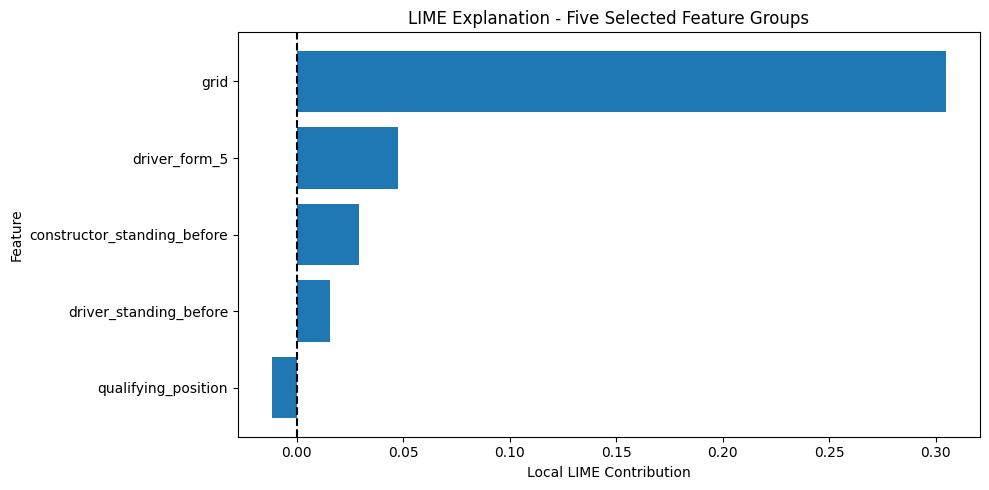

In [115]:
from lime.lime_tabular import LimeTabularExplainer

# Get all preprocessed feature names
feature_names = list(
    preprocessor.get_feature_names_out(features)
)

# Prediction function for LIME
def predict_lime(X):

    X = np.asarray(X, dtype=np.float32)

    probabilities = neural_model(
        X, training=False
    ).numpy().ravel()

    return np.column_stack([
        1 - probabilities,
        probabilities
    ])


# Create LIME explainer
lime_explainer = LimeTabularExplainer(
    training_data=X_train_scaled,
    feature_names=feature_names,
    class_names=['No Podium', 'Podium'],
    mode='classification',
    random_state=42
)


# Select one validation observation
sample_index = 0

# Explain all preprocessed inputs
lime_exp = lime_explainer.explain_instance(
    X_val_scaled[sample_index],
    predict_lime,
    labels=(1,),
    num_features=len(feature_names),
    num_samples=1000
)


# Get LIME contributions
lime_weights = dict(lime_exp.as_map()[1])

# Combine each feature with its missing indicator
grouped_lime = {}

for feature in features:

    index = feature_names.index(feature)

    contribution = lime_weights.get(index, 0)

    indicator = 'missingindicator_' + feature

    if indicator in feature_names:

        indicator_index = feature_names.index(indicator)

        contribution += lime_weights.get(indicator_index, 0)

    grouped_lime[feature] = contribution


# Convert contributions to DataFrame
lime_df = pd.DataFrame({
    'Feature': list(grouped_lime.keys()),
    'Contribution': list(grouped_lime.values())
})

lime_df = lime_df.sort_values('Contribution')

display(lime_df.round(4))


# Display prediction results
probability = predict_lime(
    X_val_scaled[sample_index:sample_index + 1]
)[0, 1]

print("Predicted Podium Probability:",
      round(float(probability), 4))

print("Actual Podium:",
      y_val.iloc[sample_index])


# Visualize grouped LIME contributions
plt.figure(figsize=(10, 5))

plt.barh(
    lime_df['Feature'],
    lime_df['Contribution']
)

plt.axvline(0, color='black', linestyle='--')

plt.title('LIME Explanation - Five Selected Feature Groups')
plt.xlabel('Local LIME Contribution')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

### 9.3 LIME Results and Interpretation

LIME was applied to one validation observation to explain
an individual prediction made by our Shallow Neural Network.

The original features and their corresponding missing-value
indicators were combined into five feature groups.

**1. Individual Prediction**

- Predicted Podium Probability: 75.23%
- Actual Podium Outcome: 1 (Podium Finish)

The model assigned a relatively high podium probability,
and the driver actually finished on the podium.

**2. Local Feature Contributions**

| Feature | LIME Contribution |
|---|---|
| Starting Grid Position | +0.3010 |
| Historical Driver Form | +0.0487 |
| Constructor Championship Standing | +0.0251 |
| Driver Championship Standing | +0.0124 |
| Qualifying Position | -0.0327 |

**3. Positive Contributions**

Starting-grid position had the strongest positive contribution
of +0.3010.

Historical driver form also contributed positively (+0.0487),
followed by constructor standings (+0.0251) and driver
standings (+0.0124).

These features pushed the local approximation toward
a higher predicted podium probability.

**4. Negative Contributions**

Qualifying position had a negative contribution of -0.0327.

This indicates that the qualifying feature group reduced
the locally approximated podium prediction for this
specific observation.

**5. Conclusion**

LIME showed that starting-grid position was the most
influential positive contributor to this individual prediction.

The results provide a local explanation of the Neural
Network's prediction rather than its overall behavior.

The contributions come from an approximate local model
and do not represent causal effects.


## 9.4 Final XAI Comparison and Conclusion

Three explainability techniques were applied to our
selected Shallow Neural Network.

**1. Permutation Importance**

Starting-grid position was the most important feature,
causing a validation PR-AUC decrease of 0.1913 when shuffled.

Qualifying position and historical driver form ranked
second and third, respectively.

**2. Global SHAP**

SHAP identified starting-grid position as the most
influential feature group, followed by historical
driver form and qualifying position.

Better starting positions and stronger recent driver
performance generally contributed positively to
predicted podium probabilities.

**3. Local LIME**

LIME explained one individual prediction with a
predicted podium probability of 75.23%.

Starting-grid position had the strongest positive
contribution (+0.3010), while qualifying position
contributed negatively (-0.0327) for this observation.

**4. Comparison with Feature-Group Ablation**

All three XAI techniques and feature-group ablation
highlighted the importance of starting-grid position.

However, historical driver form showed noticeable
SHAP and LIME contributions despite its removal
slightly improving validation PR-AUC during ablation.

This difference occurs because explainability methods
measure how the trained model uses features, while
ablation measures performance changes after retraining.

**5. Final Conclusion**

Starting-grid position consistently emerged as the
most influential feature for podium prediction.

Qualifying position, historical driver form, and
championship standings also contributed to predictions,
although their importance varied across methods.

The XAI results provide evidence about the Neural
Network's predictive behavior.

These explanations must not be interpreted as causal
effects. A feature being important to the model does
not prove that it causes a driver to finish on the podium.

# 10. Inference Function

An inference function is implemented to predict whether
a Formula 1 driver will finish on the podium using
information available before the race starts.

The function accepts the five selected features:

1. Starting Grid Position
2. Qualifying Position
3. Historical Driver Form
4. Previous Driver Championship Standing
5. Previous Constructor Championship Standing

The input is transformed using the previously fitted
preprocessing pipeline.

The trained Shallow Neural Network then predicts
the probability of a podium finish.

The classification threshold was previously selected
using validation data.

The function will be demonstrated using a complete
record and a partially missing record.

In [116]:
# Function to predict podium probability
def predict_podium(record):

    # Convert input to DataFrame
    input_df = pd.DataFrame([record])[features]

    # Apply existing preprocessing
    processed_input = preprocessor.transform(input_df)

    # Predict using the trained Neural Network
    probability = neural_model(
        processed_input,
        training=False
    ).numpy().ravel()[0]

    # Use the threshold selected during validation
    threshold = best_thresholds['Neural Network']

    prediction = int(probability >= threshold)

    return probability, prediction

## 10.1 Inference Demonstration

The inference function is tested using two observations.

**Test 1: Complete Record**

A validation observation containing all five selected
features is used to generate a podium prediction.

**Test 2: Partially Missing Record**

The same observation is used, but qualifying position
is deliberately replaced with NaN to simulate
missing information.

The inference function must successfully process
both observations without errors.

This demonstrates that the trained model can handle
missing feature values using its existing preprocessing.

In [117]:
# Select a validation record with no missing values
complete_record = X_val.dropna().iloc[0].copy()

# Create a partially missing version of the same record
missing_record = complete_record.copy()

missing_record['qualifying_position'] = np.nan


# Test 1: Complete record
print("=== COMPLETE RECORD ===")

display(pd.DataFrame([complete_record]))

probability_1, prediction_1 = predict_podium(complete_record)

print("Podium Probability:", round(float(probability_1), 4))
print("Predicted Podium:", prediction_1)


# Test 2: Partially missing record
print("\n=== PARTIALLY MISSING RECORD ===")

display(pd.DataFrame([missing_record]))

probability_2, prediction_2 = predict_podium(missing_record)

print("Podium Probability:", round(float(probability_2), 4))
print("Predicted Podium:", prediction_2)

=== COMPLETE RECORD ===


,grid,qualifying_position,driver_form_5,driver_standing_before,constructor_standing_before
24129,3.0,3.0,0.8,2.0,1.0


Podium Probability: 0.6161
Predicted Podium: 1

=== PARTIALLY MISSING RECORD ===


,grid,qualifying_position,driver_form_5,driver_standing_before,constructor_standing_before
24129,3.0,NaN,0.8,2.0,1.0


Podium Probability: 0.5543
Predicted Podium: 1


## 10.2 Inference Results and Interpretation

### 1. Complete Record

The inference function was tested using a validation
observation containing all five selected features.

Input features:
- Starting Grid Position: 3
- Qualifying Position: 3
- Historical Driver Form: 0.80
- Driver Championship Standing: 2
- Constructor Championship Standing: 1

Results:
- Predicted Podium Probability: 59.76%
- Predicted Class: 1 (Podium)

The Neural Network predicted that the driver would
finish on the podium.

### 2. Partially Missing Record

The same observation was tested after deliberately
removing its qualifying position.

Results:
- Predicted Podium Probability: 53.91%
- Predicted Class: 1 (Podium)

The model successfully generated a prediction despite
the missing qualifying information.

### 3. Effect of Missing Information

Removing qualifying position decreased the predicted
podium probability from 59.76% to 53.91%.

This represents a reduction of 5.85 percentage points.

However, the predicted classification remained unchanged.

The difference demonstrates that missing qualifying
information can influence the model's predictions.

### 4. Missing-Value Handling

The existing preprocessing pipeline handled missing
values using median imputation and missing-value indicators.

The same preprocessing fitted during training was
applied to both records.

No model retraining or modification was required.

### 5. Conclusion

The inference function successfully generated podium
predictions for both complete and partially missing
records.

This demonstrates that the trained Neural Network
can process pre-race information even when some
features are unavailable.

The prediction threshold was selected using validation
data rather than the unseen test dataset.

# 11. Final Notebook Verification

The complete Formula 1 podium prediction pipeline includes:

- Exploratory Data Analysis
- Data Cleaning and Auditing
- Three Data-Engineering Questions
- Feature Selection and Engineering
- Chronological Dataset Splitting
- Preprocessing Experiments
- Statistical Machine Learning Models
- Shallow Feedforward Neural Network
- Model Evaluation
- Feature-Group Ablation
- Explainable Artificial Intelligence (XAI)
- Inference Function

All models use pre-race information, with historical
features constructed to avoid using current-race outcomes.

The notebook is designed to execute sequentially,
reproducing the data analysis, model training,
evaluation, visualizations, and inference results.

## 11.1 Reproducibility Note

The numerical results and interpretations documented in this notebook
correspond to the first successful execution.

The notebook was subsequently rerun to verify that all cells
execute successfully from start to finish.

Minor differences in results may occur due to randomness in
model training and explainability techniques.

The original interpretations have been retained as a reference
to the first successful execution.